In [18]:

# Step 1: Import the libraries required for data analysis

import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

In [13]:

# Step 1B: Load the original e-commerce dataset

df = pd.read_csv("Ecommerce.csv")

# Display the first 5 rows
df.head()

,customer_id,session_id,visit_date,device_type,user_type,marketing_channel,product_id,product_category,unit_price,quantity,...,review_text,review_helpful_votes,payment_method,visit_day,visit_month,visit_weekday,visit_season,session_duration_bucket,revenue_normalized,location
0,1803,0,28-11-2024,2,1,2,894,6,651.57,1,...,1,0,1,28,11,3,0,Long,0.000000,209
1,7964,1,25-09-2024,2,0,4,844,2,945.27,4,...,1,0,2,25,9,2,0,Long,0.000000,213
2,6890,2,31-05-2024,1,1,0,865,0,400.44,4,...,1,0,2,31,5,4,1,Short,0.000000,10
3,4949,3,30-01-2024,1,0,2,851,3,1268.54,2,...,10,4,1,30,1,1,3,Very Long,0.305504,46
4,4896,4,25-02-2024,1,1,5,794,3,880.81,3,...,1,0,1,25,2,6,3,Very Short,0.000000,118


In [3]:

# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Check all column names
print("\nColumn names:")
print(df.columns.tolist())

# Check the data types and non-null counts
print("\nDataset information:")
df.info()

Dataset shape: (25000, 29)

Column names:
['customer_id', 'session_id', 'visit_date', 'device_type', 'user_type', 'marketing_channel', 'product_id', 'product_category', 'unit_price', 'quantity', 'discount_percent', 'discount_amount', 'revenue', 'pages_viewed', 'time_on_site_sec', 'added_to_cart', 'purchased', 'cart_abandoned', 'rating', 'review_text', 'review_helpful_votes', 'payment_method', 'visit_day', 'visit_month', 'visit_weekday', 'visit_season', 'session_duration_bucket', 'revenue_normalized', 'location']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 29 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customer_id              25000 non-null  int64  
 1   session_id               25000 non-null  int64  
 2   visit_date               25000 non-null  object 
 3   device_type              25000 non-null  int64  
 4   user_type             

In [4]:

# Step 1D: Check duplicate records

print("Exact duplicate rows:", df.duplicated().sum())

# Check whether session IDs are repeated
print("Duplicate session IDs:", df["session_id"].duplicated().sum())

# Check the number of unique customers and sessions
print("Unique customers:", df["customer_id"].nunique())
print("Unique sessions:", df["session_id"].nunique())

Exact duplicate rows: 0
Duplicate session IDs: 0
Unique customers: 8442
Unique sessions: 25000


In [5]:

# Step 1E: Inspect numerical columns

print("NUMERICAL COLUMN SUMMARY")
print(df.describe().T)

# Inspect the values used in categorical columns
categorical_columns = [
    "device_type",
    "user_type",
    "marketing_channel",
    "product_category",
    "added_to_cart",
    "purchased",
    "cart_abandoned",
    "rating",
    "payment_method",
    "visit_weekday",
    "visit_season",
    "location"
]

print("\nCATEGORICAL VALUE COUNTS")

for column in categorical_columns:
    print("\n", column)
    print(df[column].value_counts().sort_index())

NUMERICAL COLUMN SUMMARY
                        count          mean          std      min        25%  \
customer_id           25000.0   5479.930600  2593.544596  1000.00  3234.0000   
session_id            25000.0  12499.500000  7217.022701     0.00  6249.7500   
device_type           25000.0      0.705040     0.639543     0.00     0.0000   
user_type             25000.0      0.551280     0.497373     0.00     0.0000   
marketing_channel     25000.0      2.514040     1.704934     0.00     1.0000   
product_id            25000.0    449.107000   259.513787     0.00   225.0000   
product_category      25000.0      3.495240     2.285053     0.00     2.0000   
unit_price            25000.0    782.319010   476.612168    50.05   395.2225   
quantity              25000.0      2.489040     1.114563     1.00     1.0000   
discount_percent      25000.0      8.998800     9.263640     0.00     0.0000   
discount_amount       25000.0    174.997669   269.005411     0.00     0.0000   
revenue        

In [6]:

# Step 1F: Investigate dates and purchase-related columns

# 1. Check the date range
print("Earliest visit date:", df["visit_date"].min())
print("Latest visit date:", df["visit_date"].max())

# 2. Compare purchase status with revenue
print("\nPurchase status vs revenue")
print(df.groupby("purchased")["revenue"].agg(["count", "mean", "min", "max"]))

# 3. Compare cart status, purchase status and abandonment
print("\nCart and purchase combinations")
print(pd.crosstab(df["added_to_cart"], df["purchased"]))

print("\nAbandonment vs purchase")
print(pd.crosstab(df["cart_abandoned"], df["purchased"]))

# 4. Check important numerical ranges
print("\nNon-positive prices:", (df["unit_price"] <= 0).sum())
print("Non-positive quantities:", (df["quantity"] <= 0).sum())
print("Negative revenue:", (df["revenue"] < 0).sum())
print("Discounts above 100%:", (df["discount_percent"] > 100).sum())
print("Negative time on site:", (df["time_on_site_sec"] < 0).sum())

Earliest visit date: 01-01-2024
Latest visit date: 31-10-2024

Purchase status vs revenue
           count         mean    min      max
purchased                                    
0          19384     0.000000   0.00     0.00
1           5616  1801.312155  43.35  7889.36

Cart and purchase combinations
purchased          0     1
added_to_cart             
0               8883     0
1              10501  5616

Abandonment vs purchase
purchased           0     1
cart_abandoned             
0                8883  5616
1               10501     0

Non-positive prices: 0
Non-positive quantities: 0
Negative revenue: 0
Discounts above 100%: 0
Negative time on site: 0


In [7]:

# Step 1G: Check date consistency and normalized revenue

# Convert dates in a separate temporary Series for inspection
dates = pd.to_datetime(df["visit_date"], format="%d-%m-%Y", errors="coerce")

print("Invalid dates:", dates.isna().sum())

# Compare stored date components with the actual dates
print("Mismatched visit_day:", (dates.dt.day != df["visit_day"]).sum())
print("Mismatched visit_month:", (dates.dt.month != df["visit_month"]).sum())

# Check normalized revenue
print("\nRevenue vs normalized revenue")
print(df[["revenue", "revenue_normalized"]].describe())

print(
    "\nCorrelation between revenue and normalized revenue:",
    df["revenue"].corr(df["revenue_normalized"])
)

# Check whether normalized revenue is a constant scaling of revenue
print(
    "\nMaximum difference from min-max scaling:",
    (
        df["revenue_normalized"]
        - (df["revenue"] - df["revenue"].min())
        / (df["revenue"].max() - df["revenue"].min())
    ).abs().max()
)

Invalid dates: 0
Mismatched visit_day: 0
Mismatched visit_month: 0

Revenue vs normalized revenue
            revenue  revenue_normalized
count  25000.000000        25000.000000
mean     404.646762            0.051290
std     1022.391774            0.129591
min        0.000000            0.000000
25%        0.000000            0.000000
50%        0.000000            0.000000
75%        0.000000            0.000000
max     7889.360000            1.000000

Correlation between revenue and normalized revenue: 1.0

Maximum difference from min-max scaling: 4.999442526631981e-10


In [14]:
# Step 2A: Create a separate working copy
df_clean = df.copy()

# Convert visit_date into datetime format
df_clean["visit_date"] = pd.to_datetime(
    df_clean["visit_date"],
    format="%d-%m-%Y"
)

# Check the data type and date range
print("Date data type:", df_clean["visit_date"].dtype)
print("Earliest date:", df_clean["visit_date"].min())
print("Latest date:", df_clean["visit_date"].max())

Date data type: datetime64[ns]
Earliest date: 2024-01-01 00:00:00
Latest date: 2024-12-30 00:00:00


In [9]:
# Step 2B: Investigate the date range

# Convert the original date column temporarily for checking
check_dates = pd.to_datetime(
    df["visit_date"],
    format="%d-%m-%Y",
    errors="coerce"
)

print("Original latest date:", check_dates.max())
print("Working copy latest date:", df_clean["visit_date"].max())

# Display the 5 latest dates from the original dataset
print("\nFive latest dates:")
print(df.loc[check_dates.nlargest(5).index, ["visit_date"]])

Original latest date: 2024-12-30 00:00:00
Working copy latest date: 2024-12-30 00:00:00

Five latest dates:
      visit_date
298   30-12-2024
1224  30-12-2024
1250  30-12-2024
1565  30-12-2024
1579  30-12-2024


In [10]:
# Step 2C: Check date range and date-related columns

print("Earliest date:", df_clean["visit_date"].min())
print("Latest date:", df_clean["visit_date"].max())

# Compare day and month columns with the actual date
day_mismatch = (
    df_clean["visit_date"].dt.day != df_clean["visit_day"]
).sum()

month_mismatch = (
    df_clean["visit_date"].dt.month != df_clean["visit_month"]
).sum()

print("Day mismatches:", day_mismatch)
print("Month mismatches:", month_mismatch)

Earliest date: 2024-01-01 00:00:00
Latest date: 2024-12-30 00:00:00
Day mismatches: 0
Month mismatches: 0


In [11]:
# Step 2D: Check missing values
print("Missing values in each column:")
print(df_clean.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df_clean.duplicated().sum())

# Check duplicate session IDs
print("Duplicate session IDs:", df_clean["session_id"].duplicated().sum())

Missing values in each column:
customer_id                0
session_id                 0
visit_date                 0
device_type                0
user_type                  0
marketing_channel          0
product_id                 0
product_category           0
unit_price                 0
quantity                   0
discount_percent           0
discount_amount            0
revenue                    0
pages_viewed               0
time_on_site_sec           0
added_to_cart              0
purchased                  0
cart_abandoned             0
rating                     0
review_text                0
review_helpful_votes       0
payment_method             0
visit_day                  0
visit_month                0
visit_weekday              0
visit_season               0
session_duration_bucket    0
revenue_normalized         0
location                   0
dtype: int64

Duplicate rows: 0
Duplicate session IDs: 0


In [12]:
# Step 2E: Check encoded categorical values

categorical_columns = [
    "device_type",
    "user_type",
    "marketing_channel",
    "product_category",
    "payment_method",
    "visit_weekday",
    "visit_season",
    "location",
    "session_duration_bucket"
]

for column in categorical_columns:
    print("\n", column)
    print("Unique values:", df_clean[column].nunique())
    print(df_clean[column].value_counts().sort_index())


 device_type
Unique values: 3
device_type
0     9887
1    12600
2     2513
Name: count, dtype: int64

 user_type
Unique values: 2
user_type
0    11218
1    13782
Name: count, dtype: int64

 marketing_channel
Unique values: 6
marketing_channel
0    4041
1    4190
2    4281
3    4116
4    4109
5    4263
Name: count, dtype: int64

 product_category
Unique values: 8
product_category
0    3142
1    3043
2    3237
3    3040
4    3204
5    3149
6    3112
7    3073
Name: count, dtype: int64

 payment_method
Unique values: 6
payment_method
0    4227
1    4281
2    4051
3    4140
4    4229
5    4072
Name: count, dtype: int64

 visit_weekday
Unique values: 7
visit_weekday
0    3616
1    3587
2    3524
3    3630
4    3687
5    3489
6    3467
Name: count, dtype: int64

 visit_season
Unique values: 4
visit_season
0    6209
1    6247
2    6269
3    6275
Name: count, dtype: int64

 location
Unique values: 225
location
0      101
1       99
2      114
3      120
4      123
      ... 
220    105
221   

In [13]:
# Step 2F: Check purchase and cart relationships

print("Added to cart vs Purchased:")
print(pd.crosstab(
    df_clean["added_to_cart"],
    df_clean["purchased"]
))

print("\nCart abandoned vs Purchased:")
print(pd.crosstab(
    df_clean["cart_abandoned"],
    df_clean["purchased"]
))

print("\nPurchase status vs Revenue:")
print(df_clean.groupby("purchased")["revenue"].agg(
    ["count", "min", "max", "mean"]
))

Added to cart vs Purchased:
purchased          0     1
added_to_cart             
0               8883     0
1              10501  5616

Cart abandoned vs Purchased:
purchased           0     1
cart_abandoned             
0                8883  5616
1               10501     0

Purchase status vs Revenue:
           count    min      max         mean
purchased                                    
0          19384   0.00     0.00     0.000000
1           5616  43.35  7889.36  1801.312155


In [14]:
# Step 2G: Verify purchase and cart-abandonment rules

print("Purchase rate (%):",
      round(df_clean["purchased"].mean() * 100, 2))

print("\nCart abandonment values:")
print(df_clean["cart_abandoned"].value_counts())

# Check whether cart_abandoned matches the derived rule
expected_abandoned = (
    (df_clean["added_to_cart"] == 1) &
    (df_clean["purchased"] == 0)
).astype(int)

mismatches = (
    df_clean["cart_abandoned"] != expected_abandoned
).sum()

print("\nCart abandonment rule mismatches:", mismatches)

Purchase rate (%): 22.46

Cart abandonment values:
cart_abandoned
0    14499
1    10501
Name: count, dtype: int64

Cart abandonment rule mismatches: 0


In [15]:
# Step 2H: Check whether normalized revenue duplicates revenue

print("Revenue correlation:",
      df_clean["revenue"].corr(df_clean["revenue_normalized"]))

# Calculate normalized revenue using min-max scaling
minimum = df_clean["revenue"].min()
maximum = df_clean["revenue"].max()

expected_normalized = (
    (df_clean["revenue"] - minimum) / (maximum - minimum)
)

difference = (
    df_clean["revenue_normalized"] - expected_normalized
).abs()

print("Maximum scaling difference:", difference.max())
print("Rows with difference above 0.000001:",
      (difference > 0.000001).sum())

Revenue correlation: 1.0
Maximum scaling difference: 4.999442526631981e-10
Rows with difference above 0.000001: 0


In [5]:

# Step 2I: Check revenue calculation correctly

# Calculate expected revenue for each session
expected_revenue = (
    df["unit_price"] * df["quantity"]
    - df["discount_amount"]
).where(df["purchased"] == 1, 0)

# Compare expected revenue with recorded revenue
revenue_difference = (
    df["revenue"] - expected_revenue
).abs()

# Allow small rounding differences
tolerance = 0.011

print("Total sessions:", len(df))
print("Non-purchase sessions:", (df["purchased"] == 0).sum())
print("Purchased sessions:", (df["purchased"] == 1).sum())

print("\nMaximum revenue difference:",
      round(revenue_difference.max(), 4))

print("Rows with differences above tolerance:",
      (revenue_difference > tolerance).sum())

print("\nSample mismatches:")
print(
    df.loc[
        revenue_difference > tolerance,
        ["purchased", "unit_price", "quantity",
         "discount_amount", "revenue"]
    ].head()
)

Total sessions: 25000
Non-purchase sessions: 19384
Purchased sessions: 5616

Maximum revenue difference: 0.01
Rows with differences above tolerance: 0

Sample mismatches:
Empty DataFrame
Columns: [purchased, unit_price, quantity, discount_amount, revenue]
Index: []


In [17]:
# Step 2J: Check revenue calculation for purchased sessions only

purchased_df = df_clean[df_clean["purchased"] == 1].copy()

# Calculate expected revenue
expected_revenue = (
    purchased_df["unit_price"] * purchased_df["quantity"]
    - purchased_df["discount_amount"]
)

# Compare with recorded revenue
revenue_difference = (
    purchased_df["revenue"] - expected_revenue
).abs()

print("Number of purchased sessions:", len(purchased_df))

print("Maximum revenue difference:",
      revenue_difference.max())

print("Rows with difference above 0.01:",
      (revenue_difference > 0.01).sum())

# Show a few mismatches
print("\nSample mismatches:")
print(
    purchased_df.loc[
        revenue_difference > 0.01,
        ["unit_price", "quantity", "discount_percent",
         "discount_amount", "revenue"]
    ].head()
)

Number of purchased sessions: 5616
Maximum revenue difference: 0.010000000000218279
Rows with difference above 0.01: 10

Sample mismatches:
       unit_price  quantity  discount_percent  discount_amount  revenue
814        803.65         3                10           241.10  2169.86
4339       927.25         1                30           278.18   649.08
6469       688.25         1                10            68.82   619.42
13822      152.95         1                10            15.30   137.66
16033     1360.65         3                30          1224.58  2857.36


In [18]:
# Step 2K: Check discount calculation

expected_discount = (
    df_clean["unit_price"]
    * df_clean["quantity"]
    * df_clean["discount_percent"] / 100
)

discount_difference = (
    df_clean["discount_amount"] - expected_discount
).abs()

print("Maximum discount difference:",
      discount_difference.max())

print("Rows with difference above 0.02:",
      (discount_difference > 0.02).sum())

print("\nSample mismatches:")
print(
    df_clean.loc[
        discount_difference > 0.02,
        ["unit_price", "quantity", "discount_percent",
         "discount_amount"]
    ].head()
)

Maximum discount difference: 0.005000000000222826
Rows with difference above 0.02: 0

Sample mismatches:
Empty DataFrame
Columns: [unit_price, quantity, discount_percent, discount_amount]
Index: []


In [19]:
# Step 2L: Check ratings by purchase status

print("Rating summary by purchase status:")
print(
    df_clean.groupby("purchased")["rating"].agg(
        ["count", "min", "max", "mean"]
    )
)

print("\nRating value counts for non-purchased sessions:")
print(
    df_clean.loc[df_clean["purchased"] == 0, "rating"]
    .value_counts()
    .sort_index()
)

print("\nRating value counts for purchased sessions:")
print(
    df_clean.loc[df_clean["purchased"] == 1, "rating"]
    .value_counts()
    .sort_index()
)

Rating summary by purchase status:
           count  min  max      mean
purchased                           
0          19384    4    4  4.000000
1           5616    1    5  3.768519

Rating value counts for non-purchased sessions:
rating
4    19384
Name: count, dtype: int64

Rating value counts for purchased sessions:
rating
1     262
2     551
3    1110
4    1995
5    1698
Name: count, dtype: int64


In [20]:
# Step 2M: Investigate review-related columns

print("Review text value counts:")
print(df_clean["review_text"].value_counts().sort_index())

print("\nReview helpful votes summary:")
print(df_clean["review_helpful_votes"].describe())

print("\nReview text by purchase status:")
print(
    df_clean.groupby("purchased")["review_text"]
    .value_counts()
    .sort_index()
)

print("\nHelpful votes by purchase status:")
print(
    df_clean.groupby("purchased")["review_helpful_votes"]
    .agg(["min", "max", "mean"])
)

Review text value counts:
review_text
0       749
1     20494
2       163
3       730
4       764
5       717
6       163
7       157
8       156
9       174
10      733
Name: count, dtype: int64

Review helpful votes summary:
count    25000.00000
mean         5.52080
std         12.33629
min          0.00000
25%          0.00000
50%          0.00000
75%          0.00000
max         49.00000
Name: review_helpful_votes, dtype: float64

Review text by purchase status:
purchased  review_text
0          1              19384
1          0                749
           1               1110
           2                163
           3                730
           4                764
           5                717
           6                163
           7                157
           8                156
           9                174
           10               733
Name: count, dtype: int64

Helpful votes by purchase status:
           min  max       mean
purchased                     

In [21]:
# Step 2N: Check session duration buckets

print("Duration bucket summary:")
print(
    df_clean.groupby("session_duration_bucket")["time_on_site_sec"]
    .agg(["count", "min", "max", "mean"])
)

print("\nDuration bucket counts:")
print(df_clean["session_duration_bucket"].value_counts())

Duration bucket summary:
                         count   min   max         mean
session_duration_bucket                                
Long                      6254   904  1355  1131.750720
Short                     6236   454   903   676.825529
Very Long                 6240  1356  1799  1576.271795
Very Short                6270    10   453   230.778947

Duration bucket counts:
session_duration_bucket
Very Short    6270
Long          6254
Very Long     6240
Short         6236
Name: count, dtype: int64


In [22]:
# Step 2O: Final numerical range checks

print("Negative values in important columns:")

columns_to_check = [
    "unit_price",
    "quantity",
    "discount_amount",
    "revenue",
    "pages_viewed",
    "time_on_site_sec",
    "review_helpful_votes"
]

for column in columns_to_check:
    print(column, ":", (df_clean[column] < 0).sum())

print("\nBinary column checks:")

binary_columns = [
    "added_to_cart",
    "purchased",
    "cart_abandoned"
]

for column in binary_columns:
    print(column, ":", sorted(df_clean[column].unique()))

Negative values in important columns:
unit_price : 0
quantity : 0
discount_amount : 0
revenue : 0
pages_viewed : 0
time_on_site_sec : 0
review_helpful_votes : 0

Binary column checks:
added_to_cart : [np.int64(0), np.int64(1)]
purchased : [np.int64(0), np.int64(1)]
cart_abandoned : [np.int64(0), np.int64(1)]


In [23]:
# Step 0: Create a folder to save all graphs

import os
import matplotlib.pyplot as plt
import seaborn as sns

graph_folder = "RetailIQ_Graphs"

os.makedirs(graph_folder, exist_ok=True)

print("Graph folder created at:")
print(os.path.abspath(graph_folder))

Graph folder created at:
C:\Users\vishu\Downloads\DS Project\RetailIQ_Graphs


In [24]:
# Save the graph before displaying it

plt.savefig(
    os.path.join(graph_folder, "01_example_graph.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<Figure size 640x480 with 0 Axes>

In [25]:
# Step 3A: Calculate overall business metrics

total_sessions = len(df_clean)
total_customers = df_clean["customer_id"].nunique()
total_purchases = df_clean["purchased"].sum()
total_revenue = df_clean["revenue"].sum()

purchase_rate = (total_purchases / total_sessions) * 100

average_purchase_revenue = (
    df_clean.loc[df_clean["purchased"] == 1, "revenue"].mean()
)

cart_additions = df_clean["added_to_cart"].sum()

cart_abandonment_rate = (
    df_clean["cart_abandoned"].sum() / cart_additions
) * 100

# Display the results
print("Total sessions:", total_sessions)
print("Unique customers:", total_customers)
print("Total purchases:", total_purchases)
print("Total revenue:", round(total_revenue, 2))
print("Purchase rate (%):", round(purchase_rate, 2))
print("Average revenue per purchase:", round(average_purchase_revenue, 2))
print("Cart additions:", cart_additions)
print("Cart abandonment rate (%):", round(cart_abandonment_rate, 2))

Total sessions: 25000
Unique customers: 8442
Total purchases: 5616
Total revenue: 10116169.06
Purchase rate (%): 22.46
Average revenue per purchase: 1801.31
Cart additions: 16117
Cart abandonment rate (%): 65.15


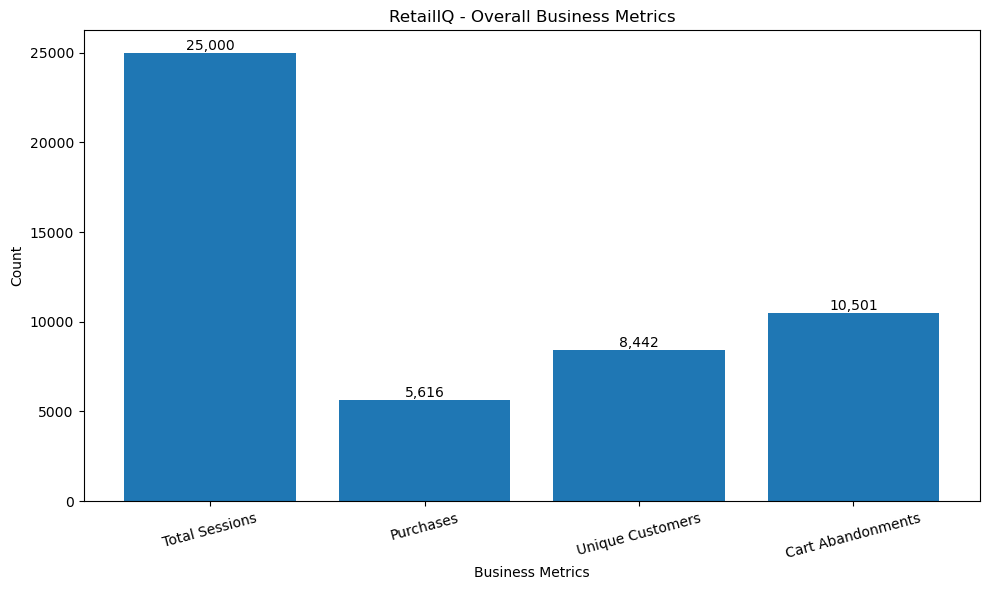

Graph saved: 01_overall_business_metrics.png


In [26]:
# Step 3B: Visualize overall business metrics

import os
import matplotlib.pyplot as plt

# Prepare the metrics for visualization
metric_names = [
    "Total Sessions",
    "Purchases",
    "Unique Customers",
    "Cart Abandonments"
]

metric_values = [
    total_sessions,
    total_purchases,
    total_customers,
    df_clean["cart_abandoned"].sum()
]

# Create a bar chart
plt.figure(figsize=(10, 6))
bars = plt.bar(metric_names, metric_values)

plt.title("RetailIQ - Overall Business Metrics")
plt.xlabel("Business Metrics")
plt.ylabel("Count")
plt.xticks(rotation=15)

# Display the value above each bar
for bar in bars:
    value = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{int(value):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

# Save the graph in our folder
plt.savefig(
    os.path.join(graph_folder, "01_overall_business_metrics.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved: 01_overall_business_metrics.png")

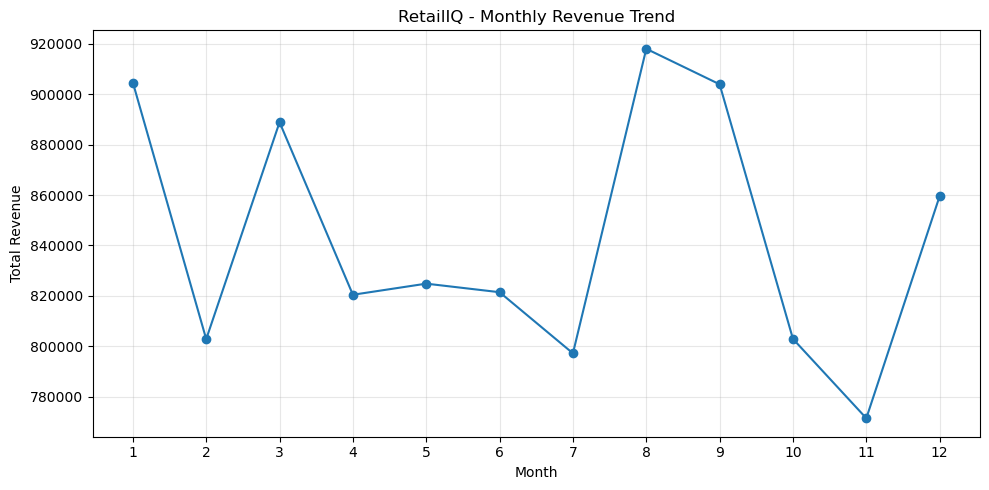

Graph saved: 02_monthly_revenue_trend.png


In [27]:

# Step 3C: Analyze monthly revenue

# Extract the month from the visit date
df_clean["month"] = df_clean["visit_date"].dt.month

# Calculate total revenue for each month
monthly_revenue = df_clean.groupby("month")["revenue"].sum()

# Plot the monthly revenue trend
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_revenue.index,
    monthly_revenue.values,
    marker="o"
)

plt.title("RetailIQ - Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)

plt.tight_layout()

# Save the graph
plt.savefig(
    os.path.join(graph_folder, "02_monthly_revenue_trend.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved: 02_monthly_revenue_trend.png")

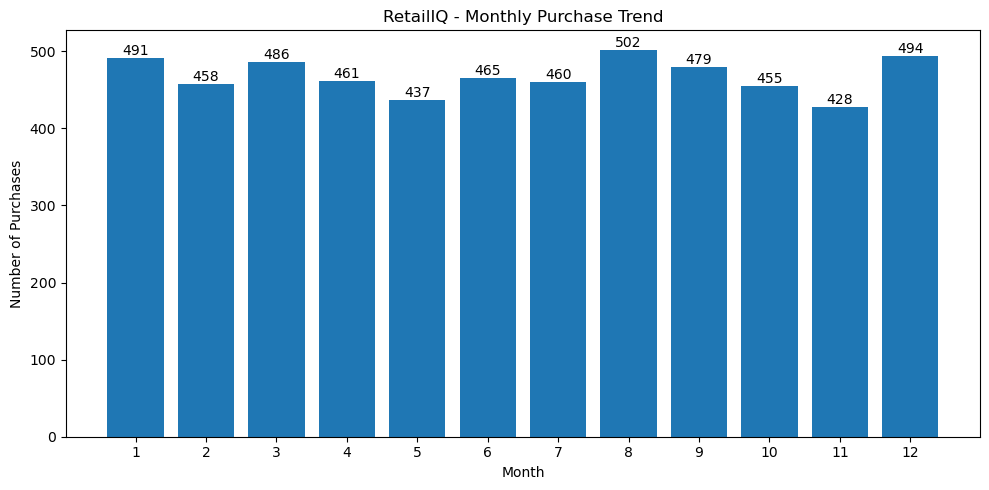

Graph saved: 03_monthly_purchase_trend.png


In [28]:

# Step 3D: Analyze monthly purchases

# Count successful purchases in each month
monthly_purchases = (
    df_clean[df_clean["purchased"] == 1]
    .groupby("month")["purchased"]
    .sum()
)

# Plot the monthly purchase trend
plt.figure(figsize=(10, 5))

plt.bar(
    monthly_purchases.index,
    monthly_purchases.values
)

plt.title("RetailIQ - Monthly Purchase Trend")
plt.xlabel("Month")
plt.ylabel("Number of Purchases")
plt.xticks(range(1, 13))

# Display purchase counts above the bars
for month, count in monthly_purchases.items():
    plt.text(month, count, str(int(count)), ha="center", va="bottom")

plt.tight_layout()

# Save the graph
plt.savefig(
    os.path.join(graph_folder, "03_monthly_purchase_trend.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved: 03_monthly_purchase_trend.png")

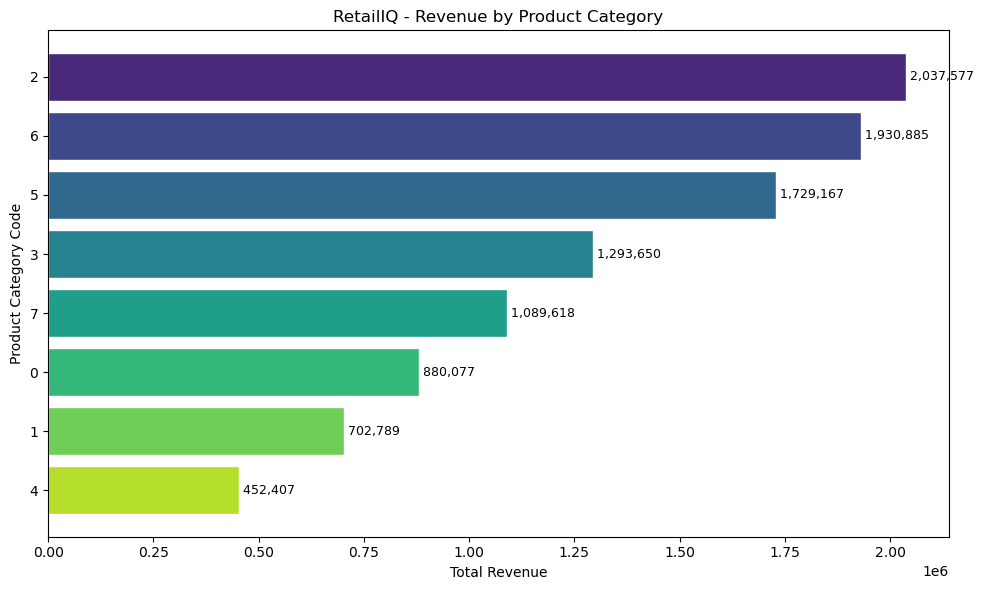

Graph saved: 04_category_revenue.png


In [29]:

# Step 3E: Analyze revenue by product category

# Calculate total revenue for each product category
category_revenue = (
    df_clean.groupby("product_category")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

# Create a colorful horizontal bar chart
plt.figure(figsize=(10, 6))

colors = sns.color_palette("viridis", len(category_revenue))

bars = plt.barh(
    category_revenue.index.astype(str),
    category_revenue.values,
    color=colors,
    edgecolor="white"
)

# Show the highest-revenue category at the top
plt.gca().invert_yaxis()

plt.title("RetailIQ - Revenue by Product Category")
plt.xlabel("Total Revenue")
plt.ylabel("Product Category Code")

# Display revenue values beside the bars
for bar in bars:
    value = bar.get_width()
    plt.text(
        value,
        bar.get_y() + bar.get_height() / 2,
        f" {value:,.0f}",
        va="center",
        fontsize=9
    )

plt.tight_layout()

# Save the graph
plt.savefig(
    os.path.join(graph_folder, "04_category_revenue.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved: 04_category_revenue.png")

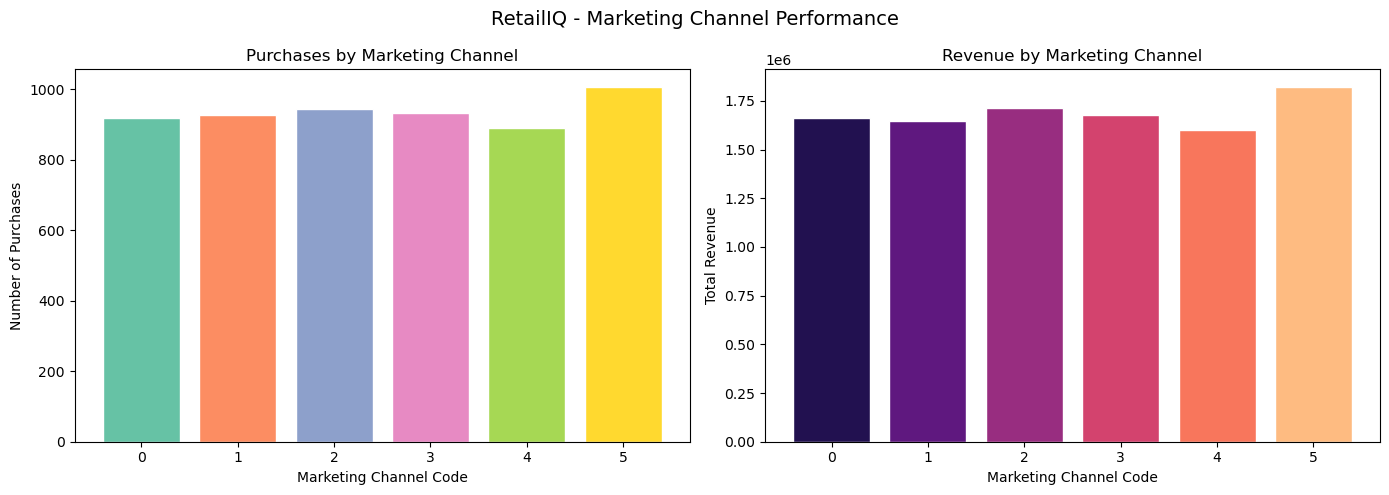

Marketing Channel Performance:


,purchases,revenue
marketing_channel,,
5,1006,1820823.79
2,943,1711962.69
3,932,1675463.47
0,918,1661328.76
1,927,1646768.68
4,890,1599821.67


Graph saved: 05_marketing_channel_performance.png


In [30]:

# Step 3F: Analyze marketing channel performance

# Calculate purchases and revenue for each marketing channel
channel_analysis = df_clean.groupby("marketing_channel").agg(
    purchases=("purchased", "sum"),
    revenue=("revenue", "sum")
)

# Create two side-by-side charts
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: Purchases by marketing channel
purchase_colors = sns.color_palette("Set2", len(channel_analysis))

axes[0].bar(
    channel_analysis.index.astype(str),
    channel_analysis["purchases"],
    color=purchase_colors,
    edgecolor="white"
)

axes[0].set_title("Purchases by Marketing Channel")
axes[0].set_xlabel("Marketing Channel Code")
axes[0].set_ylabel("Number of Purchases")

# Chart 2: Revenue by marketing channel
revenue_colors = sns.color_palette("magma", len(channel_analysis))

axes[1].bar(
    channel_analysis.index.astype(str),
    channel_analysis["revenue"],
    color=revenue_colors,
    edgecolor="white"
)

axes[1].set_title("Revenue by Marketing Channel")
axes[1].set_xlabel("Marketing Channel Code")
axes[1].set_ylabel("Total Revenue")

plt.suptitle("RetailIQ - Marketing Channel Performance", fontsize=14)
plt.tight_layout()

# Save both charts together
plt.savefig(
    os.path.join(graph_folder, "05_marketing_channel_performance.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Display the values for interpretation
print("Marketing Channel Performance:")
display(channel_analysis.sort_values("revenue", ascending=False))

print("Graph saved: 05_marketing_channel_performance.png")

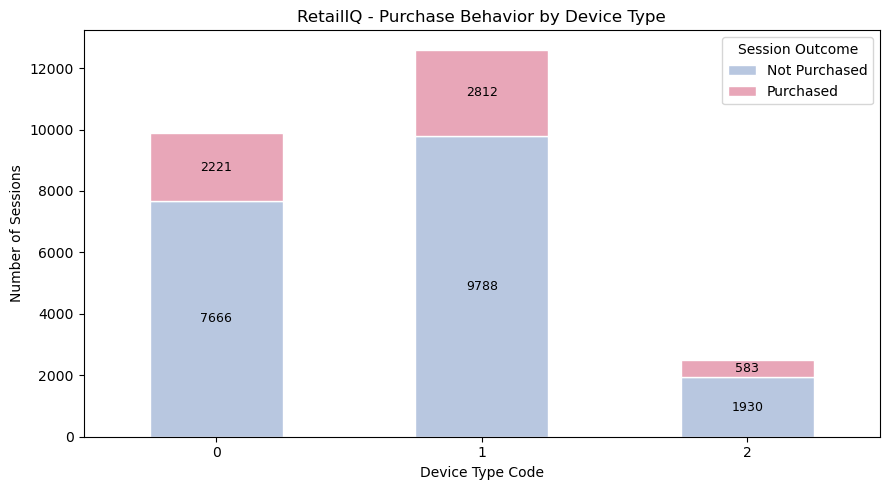

Graph saved: 06_device_purchase_behavior.png


,Not Purchased,Purchased
device_type,,
0,7666,2221
1,9788,2812
2,1930,583


In [31]:

# Step 3G: Analyze purchase behavior by device type

# Count purchases and non-purchases for each device type
device_analysis = pd.crosstab(
    df_clean["device_type"],
    df_clean["purchased"]
)

# Rename columns for readability
device_analysis.columns = ["Not Purchased", "Purchased"]

# Create a stacked bar chart
ax = device_analysis.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    color=["#B8C7E0", "#E8A6B8"],
    edgecolor="white"
)

plt.title("RetailIQ - Purchase Behavior by Device Type")
plt.xlabel("Device Type Code")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=0)
plt.legend(title="Session Outcome")

# Add values inside the stacked bars
for container in ax.containers:
    ax.bar_label(container, fmt="%d", label_type="center", fontsize=9)

plt.tight_layout()

# Save the graph
plt.savefig(
    os.path.join(graph_folder, "06_device_purchase_behavior.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved: 06_device_purchase_behavior.png")

# Display the counts
display(device_analysis)

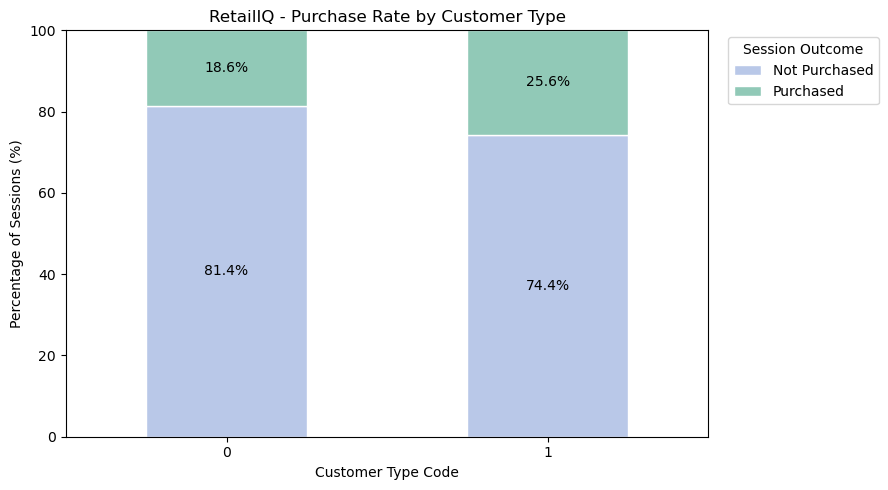

Graph saved: 07_customer_type_purchase_rate.png


,Not Purchased,Purchased
user_type,,
0,81.45,18.55
1,74.35,25.65


In [32]:

# Step 3H: Compare purchase behavior by customer type

# Calculate the percentage of each purchase outcome
customer_type_analysis = pd.crosstab(
    df_clean["user_type"],
    df_clean["purchased"],
    normalize="index"
) * 100

# Rename columns for readability
customer_type_analysis.columns = ["Not Purchased", "Purchased"]

# Create a 100% stacked bar chart
ax = customer_type_analysis.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    color=["#B9C8E8", "#91C9B7"],
    edgecolor="white"
)

plt.title("RetailIQ - Purchase Rate by Customer Type")
plt.xlabel("Customer Type Code")
plt.ylabel("Percentage of Sessions (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title="Session Outcome", bbox_to_anchor=(1.02, 1), loc="upper left")

# Add percentage labels inside the bars
for container in ax.containers:
    labels = [
        f"{value:.1f}%" if value >= 5 else ""
        for value in container.datavalues
    ]
    ax.bar_label(
        container,
        labels=labels,
        label_type="center",
        fontsize=10
    )

plt.tight_layout()

# Save the graph
plt.savefig(
    os.path.join(graph_folder, "07_customer_type_purchase_rate.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved: 07_customer_type_purchase_rate.png")

# Display the percentages
display(customer_type_analysis.round(2))

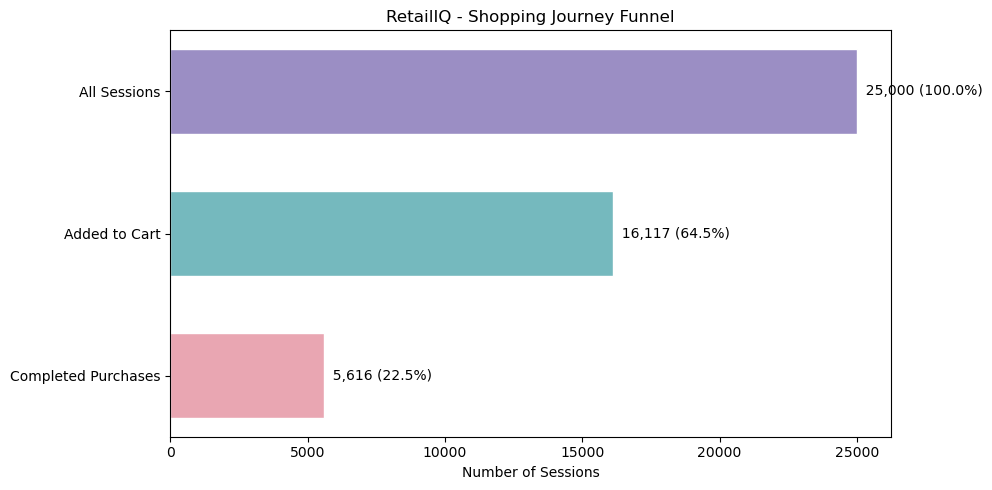

Graph saved: 08_shopping_journey_funnel.png


In [33]:

# Step 3I: Analyze the shopping journey

# Count sessions at each stage
funnel_labels = [
    "All Sessions",
    "Added to Cart",
    "Completed Purchases"
]

funnel_values = [
    len(df_clean),
    df_clean["added_to_cart"].sum(),
    df_clean["purchased"].sum()
]

# Create the funnel-style chart
plt.figure(figsize=(10, 5))

colors = ["#9B8EC4", "#75B9BE", "#E9A6B2"]

bars = plt.barh(
    funnel_labels,
    funnel_values,
    color=colors,
    edgecolor="white",
    height=0.6
)

plt.gca().invert_yaxis()
plt.title("RetailIQ - Shopping Journey Funnel")
plt.xlabel("Number of Sessions")

# Display counts and percentages of all sessions
for bar, value in zip(bars, funnel_values):
    percentage = value / len(df_clean) * 100

    plt.text(
        value,
        bar.get_y() + bar.get_height() / 2,
        f"  {value:,} ({percentage:.1f}%)",
        va="center"
    )

plt.tight_layout()

# Save the graph
plt.savefig(
    os.path.join(graph_folder, "08_shopping_journey_funnel.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved: 08_shopping_journey_funnel.png")

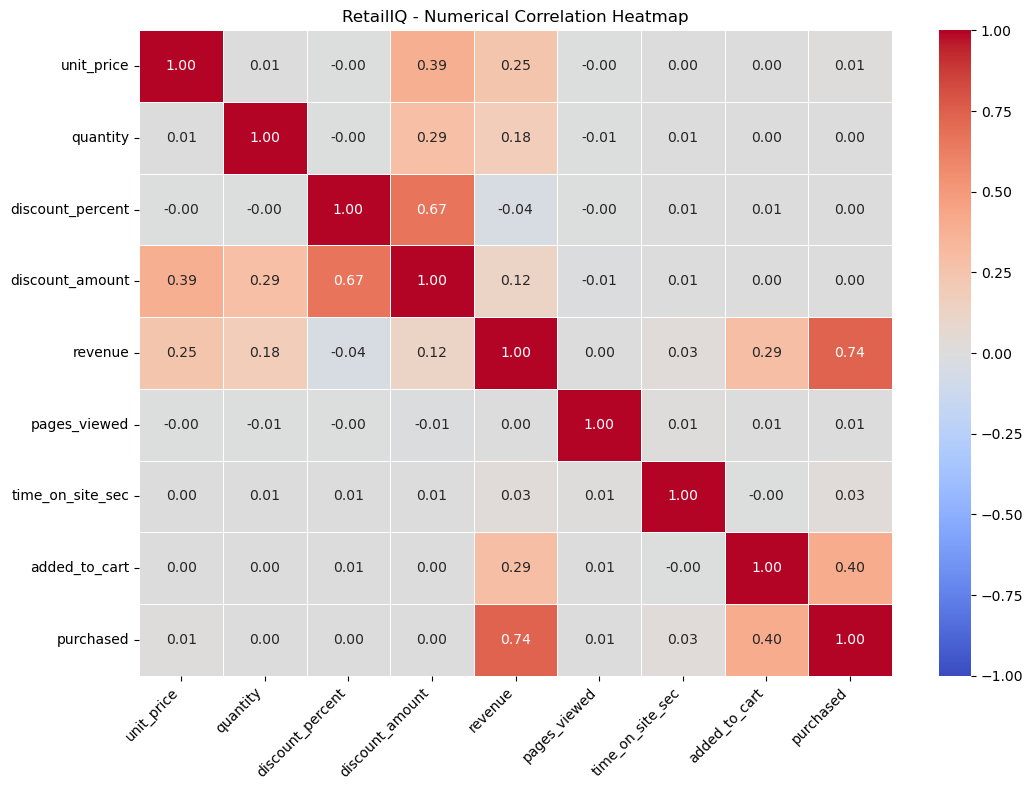

Graph saved: 09_numerical_correlation_heatmap.png


,unit_price,quantity,discount_percent,discount_amount,revenue,pages_viewed,time_on_site_sec,added_to_cart,purchased
unit_price,1.00,0.01,-0.00,0.39,0.25,-0.00,0.00,0.00,0.01
quantity,0.01,1.00,-0.00,0.29,0.18,-0.01,0.01,0.00,0.00
discount_percent,-0.00,-0.00,1.00,0.67,-0.04,-0.00,0.01,0.01,0.00
discount_amount,0.39,0.29,0.67,1.00,0.12,-0.01,0.01,0.00,0.00
revenue,0.25,0.18,-0.04,0.12,1.00,0.00,0.03,0.29,0.74
pages_viewed,-0.00,-0.01,-0.00,-0.01,0.00,1.00,0.01,0.01,0.01
time_on_site_sec,0.00,0.01,0.01,0.01,0.03,0.01,1.00,-0.00,0.03
added_to_cart,0.00,0.00,0.01,0.00,0.29,0.01,-0.00,1.00,0.40
purchased,0.01,0.00,0.00,0.00,0.74,0.01,0.03,0.40,1.00


In [34]:

# Step 3J: Analyze correlations between numerical variables

# Select useful numerical columns
numeric_columns = [
    "unit_price",
    "quantity",
    "discount_percent",
    "discount_amount",
    "revenue",
    "pages_viewed",
    "time_on_site_sec",
    "added_to_cart",
    "purchased"
]

# Calculate correlations
correlation_matrix = df_clean[numeric_columns].corr()

# Create the heatmap
plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    fmt=".2f",
    linewidths=0.5
)

plt.title("RetailIQ - Numerical Correlation Heatmap")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

# Save the graph
plt.savefig(
    os.path.join(graph_folder, "09_numerical_correlation_heatmap.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved: 09_numerical_correlation_heatmap.png")

# Display the correlation values
display(correlation_matrix.round(2))

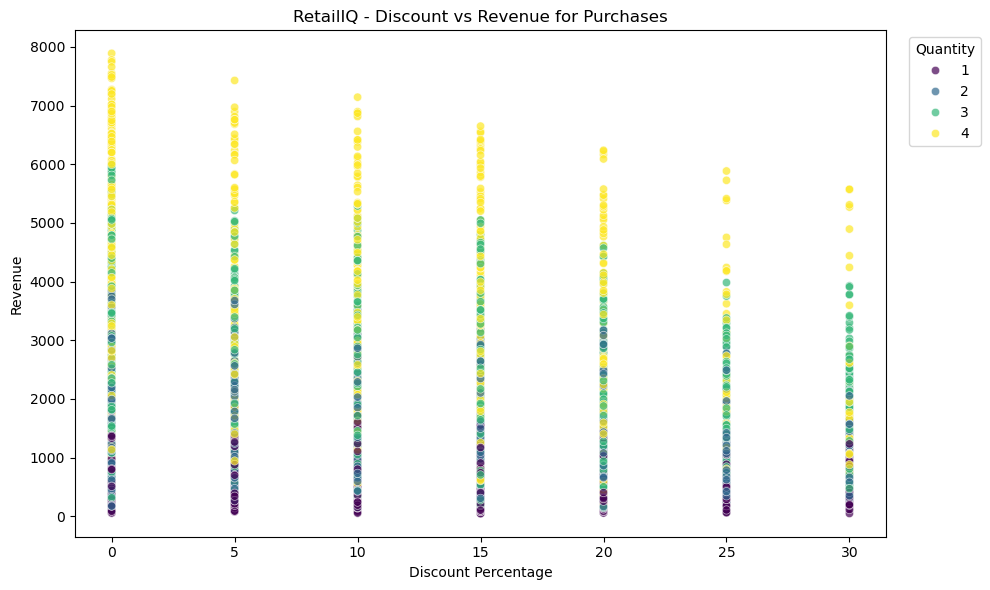

Graph saved: 10_discount_vs_revenue.png


In [35]:

# Step 3K: Analyze discounts and purchase revenue

# Select completed purchase sessions
purchase_data = df_clean[df_clean["purchased"] == 1]

# Create a scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=purchase_data,
    x="discount_percent",
    y="revenue",
    hue="quantity",
    palette="viridis",
    alpha=0.7
)

plt.title("RetailIQ - Discount vs Revenue for Purchases")
plt.xlabel("Discount Percentage")
plt.ylabel("Revenue")
plt.legend(title="Quantity", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()

# Save the graph
plt.savefig(
    os.path.join(graph_folder, "10_discount_vs_revenue.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved: 10_discount_vs_revenue.png")

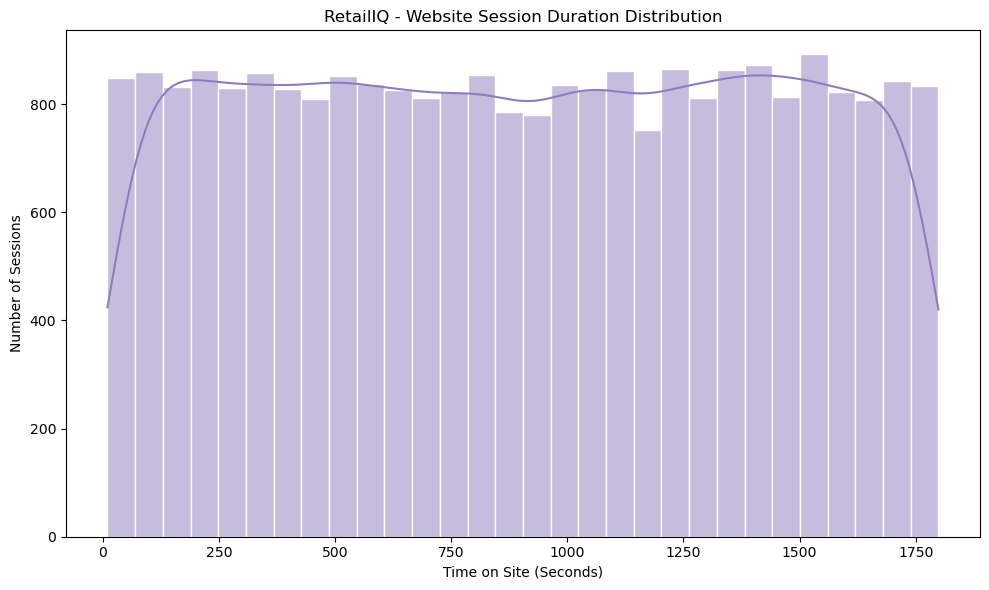

Graph saved: 11_session_duration_distribution.png
Average time on site: 903.26 seconds
Median time on site: 903.0 seconds
Minimum time: 10 seconds
Maximum time: 1799 seconds


In [36]:

# Step 3L: Analyze time spent on the website

plt.figure(figsize=(10, 6))

# Create a histogram with a density curve
sns.histplot(
    data=df_clean,
    x="time_on_site_sec",
    bins=30,
    kde=True,
    color="#8E7DBE",
    edgecolor="white"
)

plt.title("RetailIQ - Website Session Duration Distribution")
plt.xlabel("Time on Site (Seconds)")
plt.ylabel("Number of Sessions")

plt.tight_layout()

# Save the graph
plt.savefig(
    os.path.join(graph_folder, "11_session_duration_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved: 11_session_duration_distribution.png")

# Display basic statistics
print("Average time on site:", round(df_clean["time_on_site_sec"].mean(), 2), "seconds")
print("Median time on site:", round(df_clean["time_on_site_sec"].median(), 2), "seconds")
print("Minimum time:", df_clean["time_on_site_sec"].min(), "seconds")
print("Maximum time:", df_clean["time_on_site_sec"].max(), "seconds")

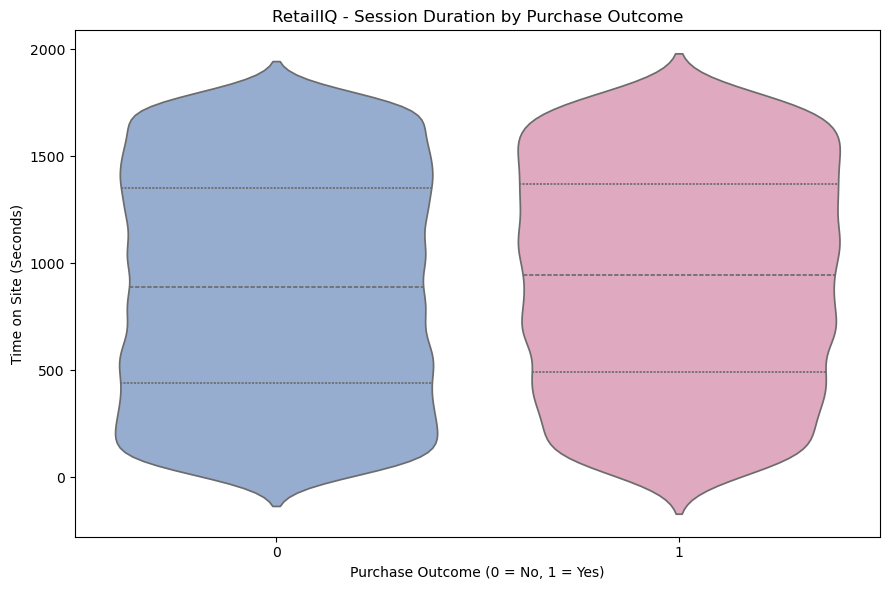

Graph saved: 12_session_duration_by_purchase.png


,count,mean,median
purchased,,,
0,19384,895.61,890.0
1,5616,929.69,942.5


In [37]:

# Step 3M: Compare session duration by purchase outcome

plt.figure(figsize=(9, 6))

sns.violinplot(
    data=df_clean,
    x="purchased",
    y="time_on_site_sec",
    hue="purchased",
    palette={0: "#8EABD9", 1: "#E8A0BF"},
    inner="quartile",
    legend=False
)

plt.title("RetailIQ - Session Duration by Purchase Outcome")
plt.xlabel("Purchase Outcome (0 = No, 1 = Yes)")
plt.ylabel("Time on Site (Seconds)")

plt.tight_layout()

# Save the graph
plt.savefig(
    os.path.join(graph_folder, "12_session_duration_by_purchase.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved: 12_session_duration_by_purchase.png")

# Compare average and median session duration
duration_summary = df_clean.groupby("purchased")["time_on_site_sec"].agg(
    ["count", "mean", "median"]
)

display(duration_summary.round(2))

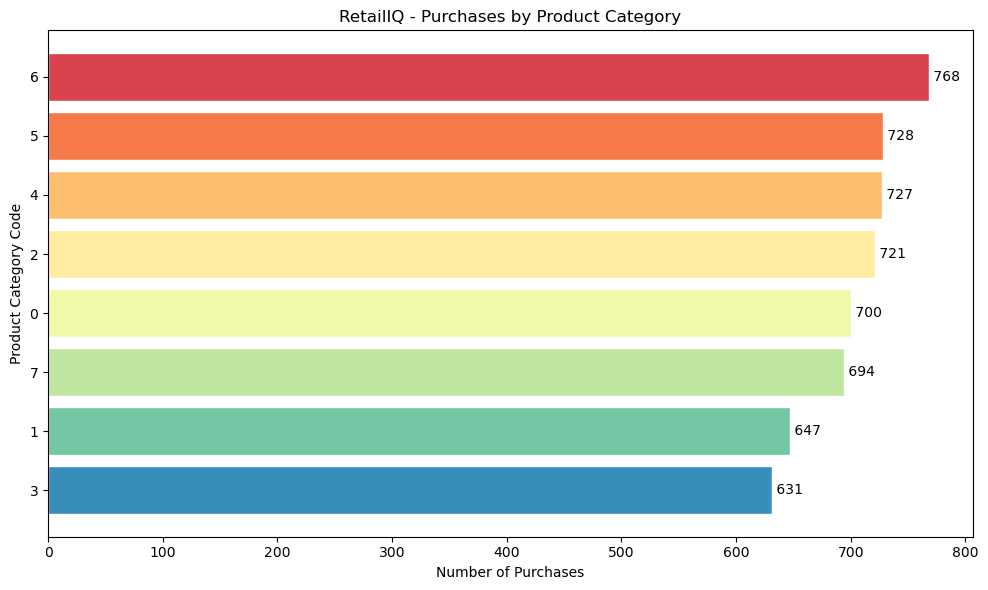

Graph saved: 13_category_purchase_counts.png


,purchase_count
product_category,
6,768
5,728
4,727
2,721
0,700
7,694
1,647
3,631


In [38]:

# Step 3N: Analyze purchases by product category

# Count completed purchases in each category
category_purchases = (
    df_clean[df_clean["purchased"] == 1]
    .groupby("product_category")["purchased"]
    .sum()
    .sort_values(ascending=False)
)

# Create a colorful horizontal bar chart
plt.figure(figsize=(10, 6))

colors = sns.color_palette("Spectral", len(category_purchases))

bars = plt.barh(
    category_purchases.index.astype(str),
    category_purchases.values,
    color=colors,
    edgecolor="white"
)

# Show the category with the most purchases at the top
plt.gca().invert_yaxis()

plt.title("RetailIQ - Purchases by Product Category")
plt.xlabel("Number of Purchases")
plt.ylabel("Product Category Code")

# Display counts beside the bars
for bar in bars:
    value = bar.get_width()
    plt.text(
        value,
        bar.get_y() + bar.get_height() / 2,
        f" {int(value):,}",
        va="center"
    )

plt.tight_layout()

# Save the graph
plt.savefig(
    os.path.join(graph_folder, "13_category_purchase_counts.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved: 13_category_purchase_counts.png")

# Display category purchase counts
display(category_purchases.to_frame("purchase_count"))

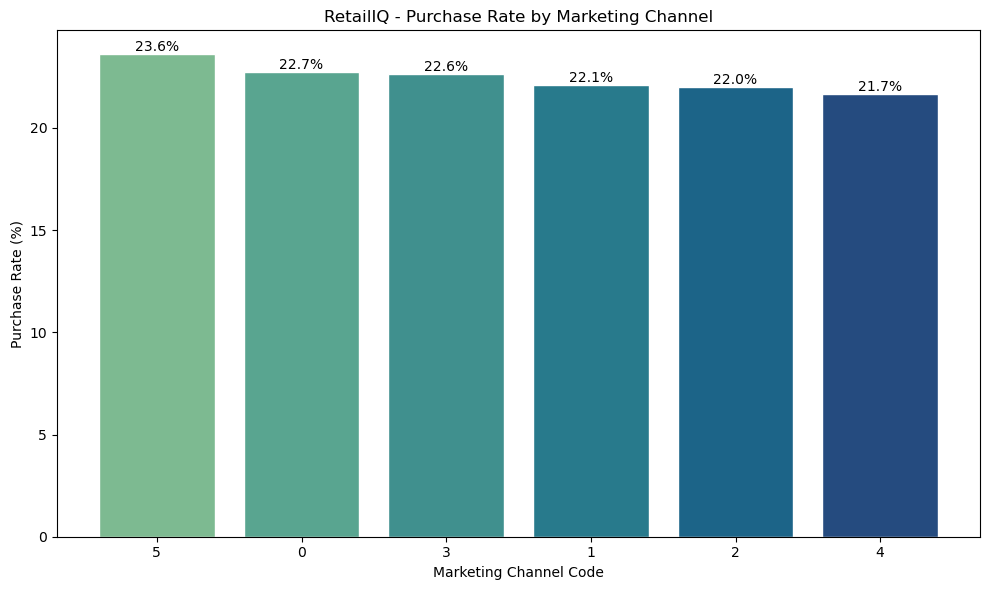

Graph saved: 14_marketing_channel_conversion_rate.png


,total_sessions,purchases,purchase_rate_percent
marketing_channel,,,
5,4263,1006,23.60
0,4041,918,22.72
3,4116,932,22.64
1,4190,927,22.12
2,4281,943,22.03
4,4109,890,21.66


In [39]:

# Step 3O: Calculate purchase rate for each marketing channel

# Calculate total sessions and purchases per channel
channel_conversion = df_clean.groupby("marketing_channel").agg(
    total_sessions=("purchased", "count"),
    purchases=("purchased", "sum")
)

# Calculate the purchase rate as a percentage
channel_conversion["purchase_rate_percent"] = (
    channel_conversion["purchases"]
    / channel_conversion["total_sessions"]
) * 100

# Sort channels by purchase rate
channel_conversion = channel_conversion.sort_values(
    "purchase_rate_percent",
    ascending=False
)

# Create a colorful bar chart
plt.figure(figsize=(10, 6))

colors = sns.color_palette("crest", len(channel_conversion))

bars = plt.bar(
    channel_conversion.index.astype(str),
    channel_conversion["purchase_rate_percent"],
    color=colors,
    edgecolor="white"
)

plt.title("RetailIQ - Purchase Rate by Marketing Channel")
plt.xlabel("Marketing Channel Code")
plt.ylabel("Purchase Rate (%)")

# Display the percentages above the bars
for bar in bars:
    value = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

# Save the graph
plt.savefig(
    os.path.join(graph_folder, "14_marketing_channel_conversion_rate.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved: 14_marketing_channel_conversion_rate.png")

# Display the detailed results
display(channel_conversion.round(2))

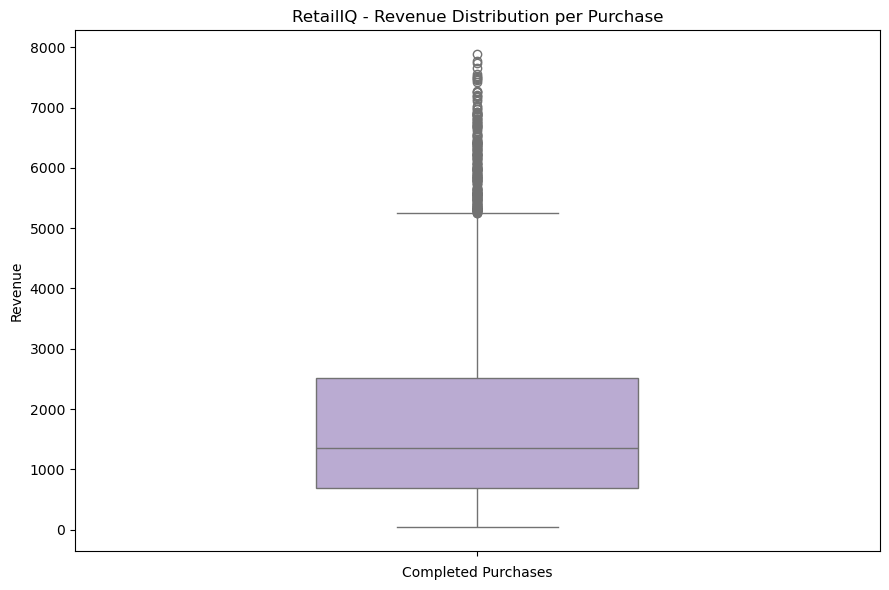

Graph saved: 15_purchase_revenue_boxplot.png
Minimum revenue: 43.35
Median revenue: 1352.26
Average revenue: 1801.31
Maximum revenue: 7889.36


In [40]:

# Step 3P: Analyze revenue distribution for completed purchases

# Select sessions with completed purchases
purchase_data = df_clean[df_clean["purchased"] == 1]

# Create a box plot
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=purchase_data,
    y="revenue",
    color="#B8A4D9",
    width=0.4
)

plt.title("RetailIQ - Revenue Distribution per Purchase")
plt.ylabel("Revenue")
plt.xlabel("Completed Purchases")

plt.tight_layout()

# Save the graph
plt.savefig(
    os.path.join(graph_folder, "15_purchase_revenue_boxplot.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved: 15_purchase_revenue_boxplot.png")

# Display revenue statistics
print("Minimum revenue:", round(purchase_data["revenue"].min(), 2))
print("Median revenue:", round(purchase_data["revenue"].median(), 2))
print("Average revenue:", round(purchase_data["revenue"].mean(), 2))
print("Maximum revenue:", round(purchase_data["revenue"].max(), 2))

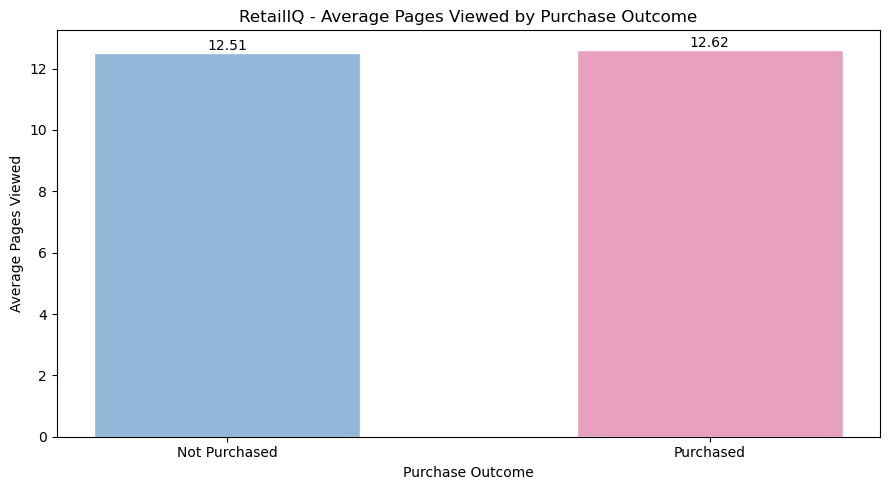

Graph saved: 16_pages_viewed_by_purchase_outcome.png


purchased
0    12.51
1    12.62
Name: pages_viewed, dtype: float64

In [41]:

# Step 3Q: Analyze page views and purchase behavior

# Create a small summary of average page views by purchase outcome
pageview_summary = df_clean.groupby("purchased")["pages_viewed"].mean()

# Plot the average page views for each outcome
plt.figure(figsize=(9, 5))

bars = plt.bar(
    ["Not Purchased", "Purchased"],
    pageview_summary.values,
    color=["#91B7D9", "#E8A0BF"],
    edgecolor="white",
    width=0.55
)

plt.title("RetailIQ - Average Pages Viewed by Purchase Outcome")
plt.xlabel("Purchase Outcome")
plt.ylabel("Average Pages Viewed")

# Display the averages above the bars
for bar in bars:
    value = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

# Save the graph
plt.savefig(
    os.path.join(graph_folder, "16_pages_viewed_by_purchase_outcome.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved: 16_pages_viewed_by_purchase_outcome.png")

# Display the averages
display(pageview_summary.round(2))

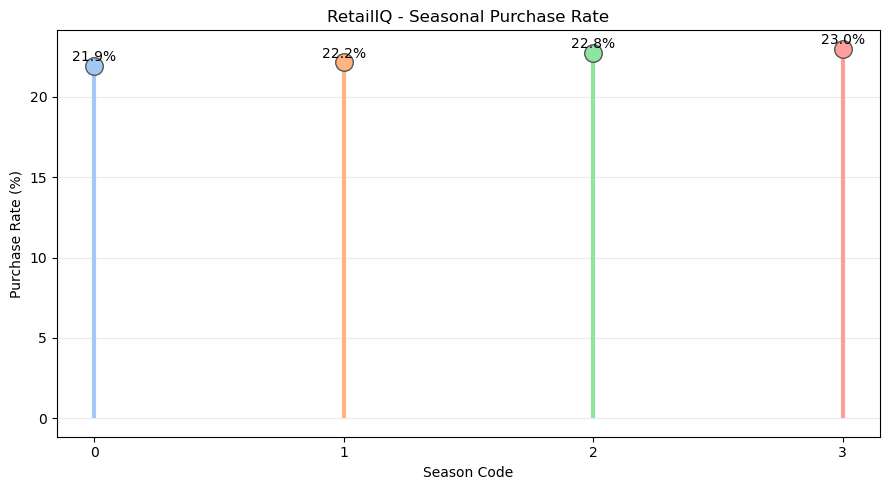

Graph saved: 17_seasonal_purchase_rate.png


,total_sessions,purchases,purchase_rate
visit_season,,,
0,6209,1362,21.94
1,6247,1384,22.15
2,6269,1427,22.76
3,6275,1443,23.00


In [42]:

# Step 3R: Analyze purchase rates by season

# Calculate sessions and purchases for each season
season_analysis = df_clean.groupby("visit_season").agg(
    total_sessions=("purchased", "count"),
    purchases=("purchased", "sum")
)

# Calculate purchase rate as a percentage
season_analysis["purchase_rate"] = (
    season_analysis["purchases"]
    / season_analysis["total_sessions"]
) * 100

# Sort season codes
season_analysis = season_analysis.sort_index()

# Create a lollipop chart
plt.figure(figsize=(9, 5))

colors = sns.color_palette("pastel", len(season_analysis))

for position, (season, row) in enumerate(season_analysis.iterrows()):
    plt.vlines(
        season,
        0,
        row["purchase_rate"],
        color=colors[position],
        linewidth=3
    )

    plt.scatter(
        season,
        row["purchase_rate"],
        color=colors[position],
        s=160,
        edgecolor="#555555",
        zorder=3
    )

    plt.text(
        season,
        row["purchase_rate"] + 0.3,
        f'{row["purchase_rate"]:.1f}%',
        ha="center"
    )

plt.title("RetailIQ - Seasonal Purchase Rate")
plt.xlabel("Season Code")
plt.ylabel("Purchase Rate (%)")
plt.xticks(season_analysis.index)
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()

# Save the graph
plt.savefig(
    os.path.join(graph_folder, "17_seasonal_purchase_rate.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved: 17_seasonal_purchase_rate.png")

# Display the seasonal results
display(season_analysis.round(2))

In [43]:

# Step 4A: Summarize important EDA findings

# 1. Best and lowest revenue product categories
category_revenue_summary = df_clean.groupby(
    "product_category"
)["revenue"].sum()

print("Product Category with Highest Revenue:",
      category_revenue_summary.idxmax())

print("Product Category with Lowest Revenue:",
      category_revenue_summary.idxmin())

# 2. Best and lowest purchase-rate marketing channels
channel_summary = df_clean.groupby("marketing_channel").agg(
    sessions=("purchased", "count"),
    purchases=("purchased", "sum")
)

channel_summary["purchase_rate"] = (
    channel_summary["purchases"] / channel_summary["sessions"]
) * 100

print("\nMarketing Channel with Highest Purchase Rate:",
      channel_summary["purchase_rate"].idxmax())

print("Marketing Channel with Lowest Purchase Rate:",
      channel_summary["purchase_rate"].idxmin())

# 3. Purchase rates by customer type
customer_summary = df_clean.groupby("user_type").agg(
    sessions=("purchased", "count"),
    purchases=("purchased", "sum")
)

customer_summary["purchase_rate"] = (
    customer_summary["purchases"] / customer_summary["sessions"]
) * 100

print("\nPurchase Rate by Customer Type:")
display(customer_summary.round(2))

# 4. Purchase rates by season
season_summary = df_clean.groupby("visit_season").agg(
    sessions=("purchased", "count"),
    purchases=("purchased", "sum")
)

season_summary["purchase_rate"] = (
    season_summary["purchases"] / season_summary["sessions"]
) * 100

print("\nPurchase Rate by Season:")
display(season_summary.round(2))

# 5. Monthly revenue comparison
monthly_summary = df_clean.groupby("month")["revenue"].sum()

print("\nMonth with Highest Revenue:", monthly_summary.idxmax())
print("Month with Lowest Revenue:", monthly_summary.idxmin())

Product Category with Highest Revenue: 2
Product Category with Lowest Revenue: 4

Marketing Channel with Highest Purchase Rate: 5
Marketing Channel with Lowest Purchase Rate: 4

Purchase Rate by Customer Type:


,sessions,purchases,purchase_rate
user_type,,,
0,11218,2081,18.55
1,13782,3535,25.65



Purchase Rate by Season:


,sessions,purchases,purchase_rate
visit_season,,,
0,6209,1362,21.94
1,6247,1384,22.15
2,6269,1427,22.76
3,6275,1443,23.00



Month with Highest Revenue: 8
Month with Lowest Revenue: 11


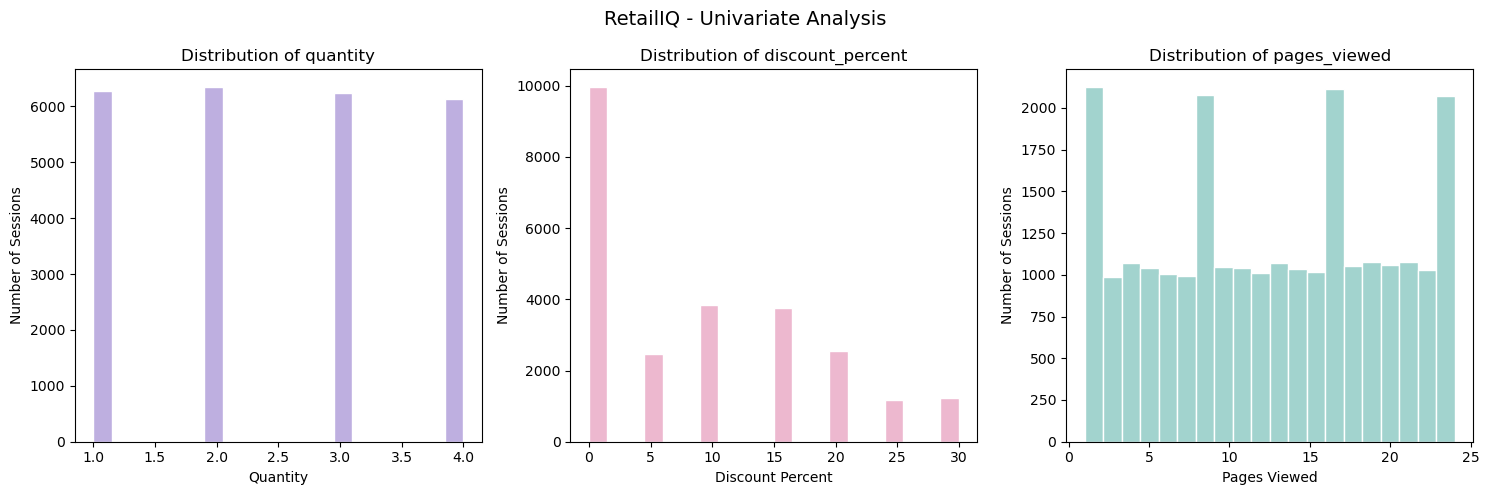

Graph saved: 18_univariate_numerical_distributions.png


,quantity,discount_percent,pages_viewed
count,25000.00,25000.00,25000.00
mean,2.49,9.00,12.54
std,1.11,9.26,6.93
min,1.00,0.00,1.00
25%,1.00,0.00,7.00
50%,2.00,10.00,13.00
75%,3.00,15.00,19.00
max,4.00,30.00,24.00


In [44]:

# Step 4C.1: Univariate analysis of numerical variables

# Select numerical variables to analyze
columns_to_plot = [
    "quantity",
    "discount_percent",
    "pages_viewed"
]

# Choose a different color for each variable
plot_colors = ["#A994D6", "#E8A0BF", "#83C5BE"]

# Create three histograms
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, column in enumerate(columns_to_plot):

    # Plot the distribution of one variable
    sns.histplot(
        data=df_clean,
        x=column,
        bins=20,
        color=plot_colors[i],
        edgecolor="white",
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution of {column}")
    axes[i].set_xlabel(column.replace("_", " ").title())
    axes[i].set_ylabel("Number of Sessions")

plt.suptitle("RetailIQ - Univariate Analysis", fontsize=14)
plt.tight_layout()

# Save the graph
plt.savefig(
    os.path.join(graph_folder, "18_univariate_numerical_distributions.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved: 18_univariate_numerical_distributions.png")

# Display descriptive statistics
display(df_clean[columns_to_plot].describe().round(2))

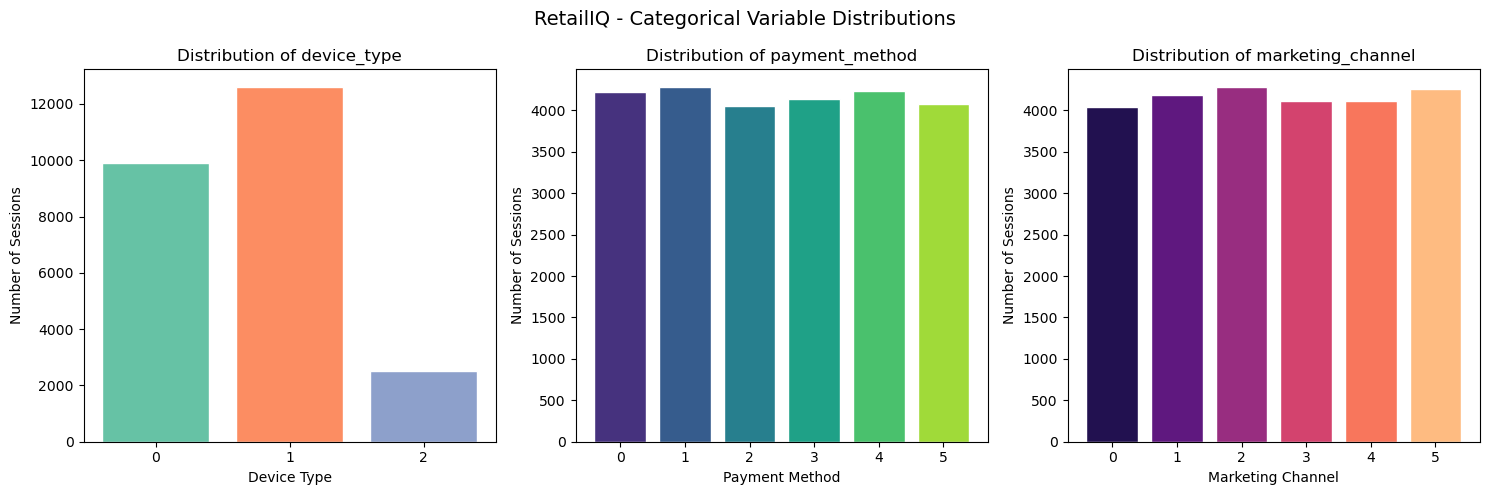

Graph saved: 19_categorical_variable_distributions.png

Counts for device_type:


,session_count
device_type,
0,9887
1,12600
2,2513



Counts for payment_method:


,session_count
payment_method,
0,4227
1,4281
2,4051
3,4140
4,4229
5,4072



Counts for marketing_channel:


,session_count
marketing_channel,
0,4041
1,4190
2,4281
3,4116
4,4109
5,4263


In [45]:

# Step 4C.2: Univariate analysis of categorical variables

# Select categorical variables
categorical_columns = [
    "device_type",
    "payment_method",
    "marketing_channel"
]

# Create three bar charts with different color palettes
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

palettes = ["Set2", "viridis", "magma"]

for i, column in enumerate(categorical_columns):

    # Count sessions in each category
    category_counts = df_clean[column].value_counts().sort_index()

    # Plot category counts
    colors = sns.color_palette(
        palettes[i],
        n_colors=len(category_counts)
    )

    axes[i].bar(
        category_counts.index.astype(str),
        category_counts.values,
        color=colors,
        edgecolor="white"
    )

    axes[i].set_title(f"Distribution of {column}")
    axes[i].set_xlabel(column.replace("_", " ").title())
    axes[i].set_ylabel("Number of Sessions")

plt.suptitle("RetailIQ - Categorical Variable Distributions", fontsize=14)
plt.tight_layout()

# Save the graph
plt.savefig(
    os.path.join(graph_folder, "19_categorical_variable_distributions.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved: 19_categorical_variable_distributions.png")

# Display category counts
for column in categorical_columns:
    print(f"\nCounts for {column}:")
    display(df_clean[column].value_counts().sort_index().to_frame("session_count"))

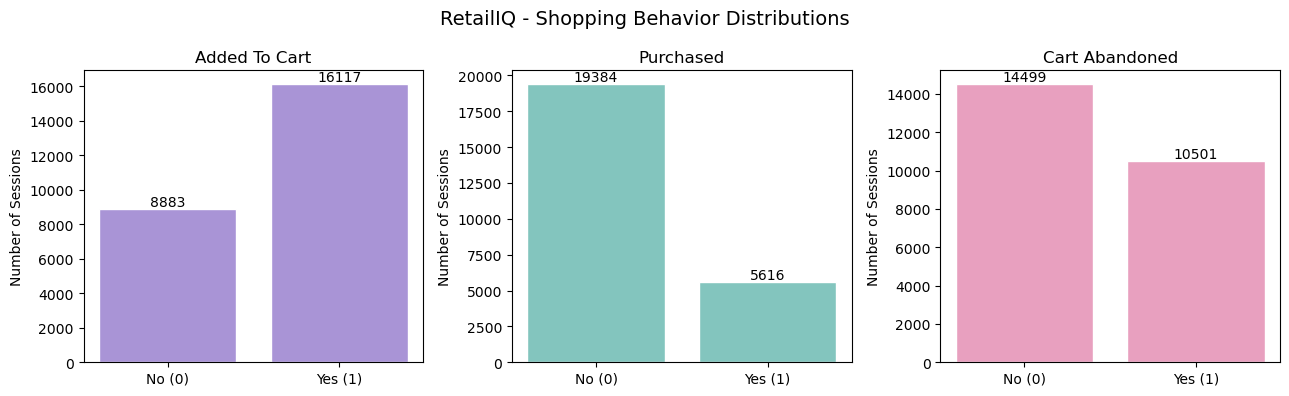

Graph saved: 20_shopping_behavior_distributions.png

added_to_cart:


,Count,Percentage
added_to_cart,,
0,8883,35.53
1,16117,64.47



purchased:


,Count,Percentage
purchased,,
0,19384,77.54
1,5616,22.46



cart_abandoned:


,Count,Percentage
cart_abandoned,,
0,14499,58.0
1,10501,42.0


In [46]:

# Step 4C.3: Univariate analysis of shopping behavior

# Select binary shopping behavior variables
behavior_columns = [
    "added_to_cart",
    "purchased",
    "cart_abandoned"
]

# Create three bar charts
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

colors = ["#A994D6", "#83C5BE", "#E8A0BF"]

for i, column in enumerate(behavior_columns):

    # Count zero and one values
    behavior_counts = df_clean[column].value_counts().reindex(
        [0, 1], fill_value=0
    )

    # Plot the counts
    axes[i].bar(
        ["No (0)", "Yes (1)"],
        behavior_counts.values,
        color=colors[i],
        edgecolor="white"
    )

    axes[i].set_title(column.replace("_", " ").title())
    axes[i].set_ylabel("Number of Sessions")

    # Show the count above each bar
    for j, value in enumerate(behavior_counts.values):
        axes[i].text(j, value, str(value), ha="center", va="bottom")

plt.suptitle("RetailIQ - Shopping Behavior Distributions", fontsize=14)
plt.tight_layout()

# Save the graph
plt.savefig(
    os.path.join(graph_folder, "20_shopping_behavior_distributions.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved: 20_shopping_behavior_distributions.png")

# Display counts and percentages
for column in behavior_columns:
    print(f"\n{column}:")
    display(
        pd.DataFrame({
            "Count": df_clean[column].value_counts().sort_index(),
            "Percentage": (
                df_clean[column].value_counts(normalize=True).sort_index() * 100
            ).round(2)
        })
    )

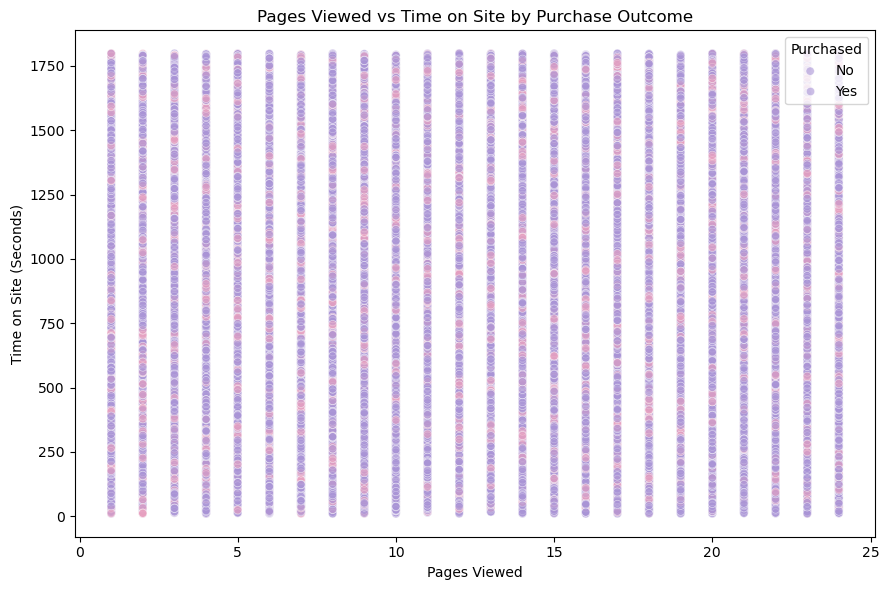

Graph saved: 21_pages_vs_time_by_purchase.png


In [47]:

# Step 4C.4: Bivariate analysis
# Relationship between pages viewed and time spent on the website

plt.figure(figsize=(9, 6))

# Compare browsing behavior for purchased and non-purchased sessions
sns.scatterplot(
    data=df_clean,
    x="pages_viewed",
    y="time_on_site_sec",
    hue="purchased",
    palette={0: "#A994D6", 1: "#E8A0BF"},
    alpha=0.6
)

plt.title("Pages Viewed vs Time on Site by Purchase Outcome")
plt.xlabel("Pages Viewed")
plt.ylabel("Time on Site (Seconds)")
plt.legend(title="Purchased", labels=["No", "Yes"])
plt.tight_layout()

# Save the graph
plt.savefig(
    os.path.join(graph_folder, "21_pages_vs_time_by_purchase.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved: 21_pages_vs_time_by_purchase.png")

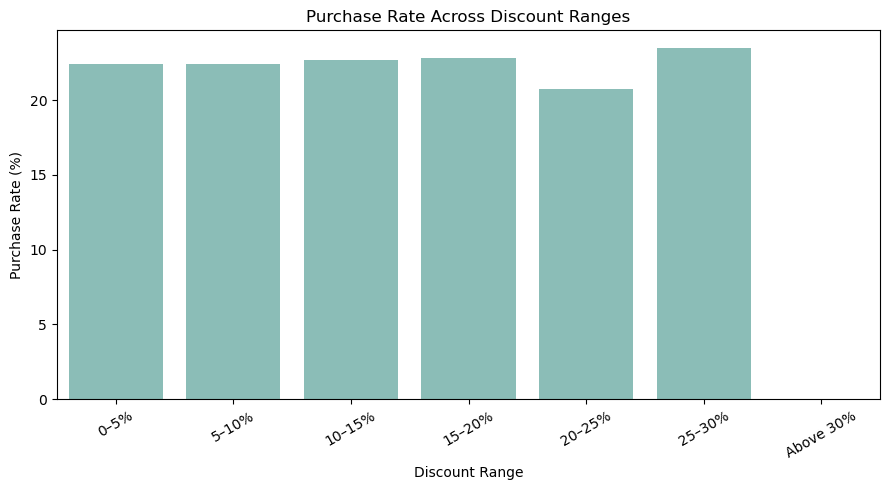

Graph saved: 22_discount_vs_purchase_rate.png


,discount_group,purchase_rate
0,0–5%,22.41
1,5–10%,22.39
2,10–15%,22.71
3,15–20%,22.79
4,20–25%,20.74
5,25–30%,23.49
6,Above 30%,NaN


In [48]:

# Step 4C.5: Analyze purchase rate across discount levels

# Group discount percentages into ranges
df_clean["discount_group"] = pd.cut(
    df_clean["discount_percent"],
    bins=[-0.01, 5, 10, 15, 20, 25, 30, 100],
    labels=["0–5%", "5–10%", "10–15%", "15–20%",
            "20–25%", "25–30%", "Above 30%"],
    include_lowest=True
)

# Calculate purchase rate for each discount group
discount_purchase = (
    df_clean.groupby("discount_group", observed=False)["purchased"]
    .mean()
    .mul(100)
    .reset_index(name="purchase_rate")
)

# Plot purchase rate
plt.figure(figsize=(9, 5))

sns.barplot(
    data=discount_purchase,
    x="discount_group",
    y="purchase_rate",
    color="#83C5BE"
)

plt.title("Purchase Rate Across Discount Ranges")
plt.xlabel("Discount Range")
plt.ylabel("Purchase Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()

# Save the graph
plt.savefig(
    os.path.join(graph_folder, "22_discount_vs_purchase_rate.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved: 22_discount_vs_purchase_rate.png")

# Display the calculated purchase rates
display(discount_purchase.round(2))

device_type,0,1,2
user_type,,,
0,18.19,18.48,20.28
1,25.96,25.40,25.66


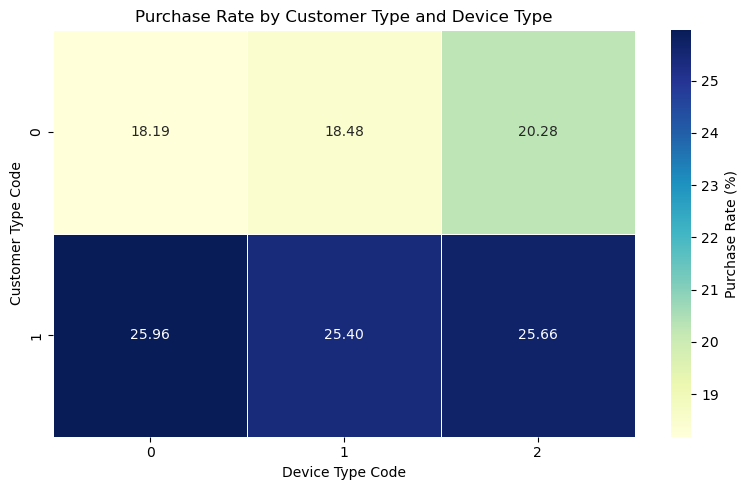

Graph saved: 23_customer_device_purchase_heatmap.png


In [49]:

# Step 4C.6: Multivariate analysis
# Compare purchase rates by customer type and device type

purchase_pivot = df_clean.pivot_table(
    index="user_type",
    columns="device_type",
    values="purchased",
    aggfunc="mean"
) * 100

# Display the purchase rates
display(purchase_pivot.round(2))

# Create a heatmap
plt.figure(figsize=(8, 5))

sns.heatmap(
    purchase_pivot,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "Purchase Rate (%)"}
)

plt.title("Purchase Rate by Customer Type and Device Type")
plt.xlabel("Device Type Code")
plt.ylabel("Customer Type Code")
plt.tight_layout()

# Save the graph
plt.savefig(
    os.path.join(graph_folder, "23_customer_device_purchase_heatmap.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved: 23_customer_device_purchase_heatmap.png")

user_type,0,1
marketing_channel,,
0,18.83,26.10
1,18.72,24.89
2,19.08,24.34
3,17.97,26.50
4,17.98,24.65
5,18.71,27.44


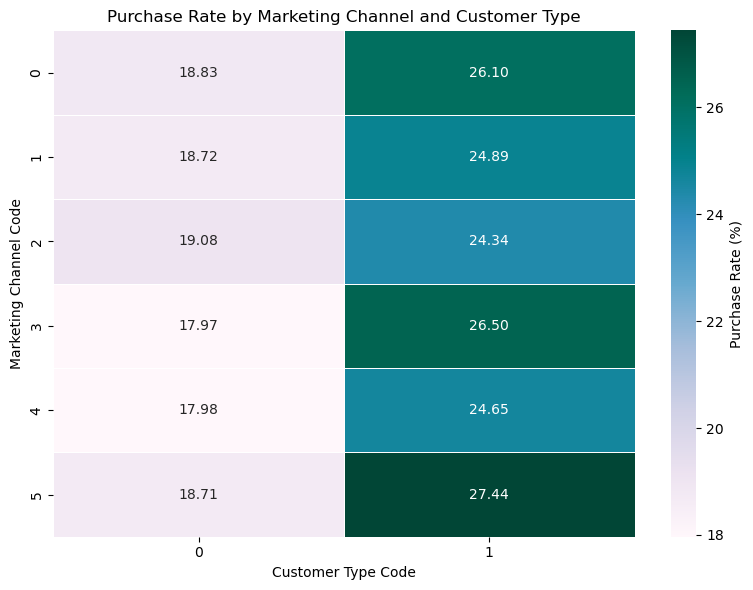

Graph saved: 24_channel_customer_purchase_heatmap.png


In [51]:

# Step 4C.7: Marketing Channel vs Customer Type

# Calculate purchase rate for each combination
channel_customer_pivot = df_clean.pivot_table(
    index="marketing_channel",
    columns="user_type",
    values="purchased",
    aggfunc="mean"
) * 100

# Display the purchase rates
display(channel_customer_pivot.round(2))

# Create the heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    channel_customer_pivot,
    annot=True,
    fmt=".2f",
    cmap="PuBuGn",
    linewidths=0.5,
    cbar_kws={"label": "Purchase Rate (%)"}
)

plt.title("Purchase Rate by Marketing Channel and Customer Type")
plt.xlabel("Customer Type Code")
plt.ylabel("Marketing Channel Code")
plt.tight_layout()

# Save the graph in our project folder
plt.savefig(
    os.path.join(
        graph_folder,
        "24_channel_customer_purchase_heatmap.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved: 24_channel_customer_purchase_heatmap.png")

In [52]:

# Check whether any discount groups have no sessions
discount_group_check = df_clean["discount_group"].value_counts(
    sort=False,
    dropna=False
)

print("Session count in each discount group:")
display(discount_group_check.to_frame("session_count"))

print("Missing discount-group values:",
      df_clean["discount_group"].isna().sum())

print("Discount percentage range:")
print(df_clean["discount_percent"].min(),
      "to",
      df_clean["discount_percent"].max())

Session count in each discount group:


,session_count
discount_group,
0–5%,12428
5–10%,3837
10–15%,3748
15–20%,2562
20–25%,1186
25–30%,1239
Above 30%,0


Missing discount-group values: 0
Discount percentage range:
0 to 30


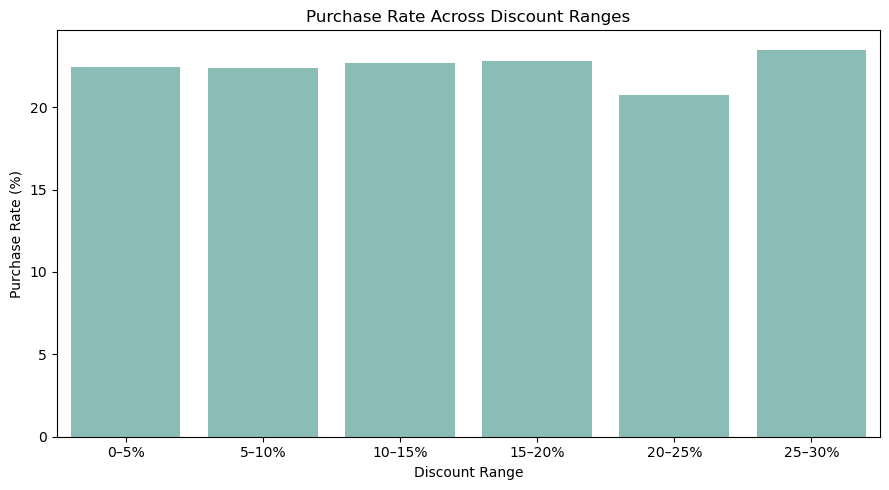

Corrected graph saved successfully.


,discount_group,purchase_rate
0,0–5%,22.41
1,5–10%,22.39
2,10–15%,22.71
3,15–20%,22.79
4,20–25%,20.74
5,25–30%,23.49


In [53]:

# Correct the discount groups using the actual data range

df_clean["discount_group"] = pd.cut(
    df_clean["discount_percent"],
    bins=[-0.01, 5, 10, 15, 20, 25, 30],
    labels=["0–5%", "5–10%", "10–15%", "15–20%", "20–25%", "25–30%"],
    include_lowest=True
)

# Calculate purchase rate for each discount group
discount_purchase = (
    df_clean.groupby("discount_group", observed=True)["purchased"]
    .mean()
    .mul(100)
    .reset_index(name="purchase_rate")
)

# Plot the corrected purchase rates
plt.figure(figsize=(9, 5))

sns.barplot(
    data=discount_purchase,
    x="discount_group",
    y="purchase_rate",
    color="#83C5BE"
)

plt.title("Purchase Rate Across Discount Ranges")
plt.xlabel("Discount Range")
plt.ylabel("Purchase Rate (%)")
plt.tight_layout()

# Save the corrected graph
plt.savefig(
    os.path.join(graph_folder, "22_discount_vs_purchase_rate.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Corrected graph saved successfully.")
display(discount_purchase.round(2))

In [15]:

# Step 5.1: Prepare data for RFM feature engineering

# Keep only sessions where a purchase was completed
purchase_data = df_clean[df_clean["purchased"] == 1].copy()

# Check the purchase records
print("Total purchase records:", len(purchase_data))
print("Unique purchasing customers:", purchase_data["customer_id"].nunique())
print("Earliest purchase date:", purchase_data["visit_date"].min())
print("Latest purchase date:", purchase_data["visit_date"].max())

# Check whether any purchase records have missing RFM inputs
print("\nMissing customer IDs:", purchase_data["customer_id"].isna().sum())
print("Missing purchase dates:", purchase_data["visit_date"].isna().sum())
print("Missing revenue values:", purchase_data["revenue"].isna().sum())

Total purchase records: 5616
Unique purchasing customers: 4176
Earliest purchase date: 2024-01-01 00:00:00
Latest purchase date: 2024-12-30 00:00:00

Missing customer IDs: 0
Missing purchase dates: 0
Missing revenue values: 0


In [16]:

# Step 5.2: Calculate customer-level RFM values

# Set the reference date to one day after the latest recorded visit
reference_date = df_clean["visit_date"].max() + pd.Timedelta(days=1)

# Calculate Recency, Frequency, and Monetary value for each customer
rfm = purchase_data.groupby("customer_id").agg(
    Recency=("visit_date", lambda dates: (reference_date - dates.max()).days),
    Frequency=("session_id", "nunique"),
    Monetary=("revenue", "sum")
).reset_index()

# Display the first five customer records
print("Reference date:", reference_date.date())
print("Number of customers in RFM:", len(rfm))

display(rfm.head())

# Display summary statistics
display(rfm[["Recency", "Frequency", "Monetary"]].describe().round(2))

Reference date: 2024-12-31
Number of customers in RFM: 4176


,customer_id,Recency,Frequency,Monetary
0,1000,248,1,1228.72
1,1003,89,1,1681.96
2,1008,49,1,1546.42
3,1009,100,3,4616.63
4,1014,318,1,2423.92


,Recency,Frequency,Monetary
count,4176.00,4176.00,4176.00
mean,164.59,1.34,2422.45
std,105.23,0.62,2021.81
min,1.00,1.00,43.35
25%,74.00,1.00,903.81
50%,154.00,1.00,1852.71
75%,253.00,2.00,3370.91
max,365.00,5.00,15955.15


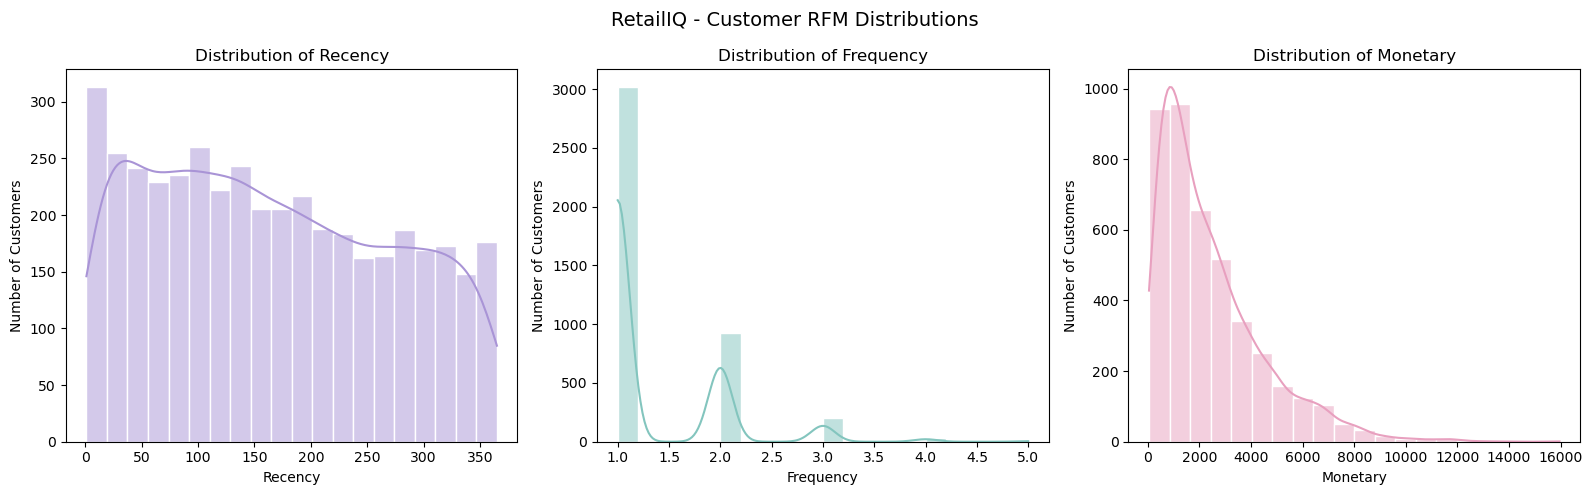

Graph saved: 25_rfm_distributions.png


In [23]:

# Step 5.3: Visualize the RFM distributions

# Select the RFM features
rfm_columns = ["Recency", "Frequency", "Monetary"]

# Create three distribution plots
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

plot_colors = ["#A994D6", "#83C5BE", "#E8A0BF"]

for i, column in enumerate(rfm_columns):

    # Plot the distribution of each RFM feature
    sns.histplot(
        data=rfm,
        x=column,
        bins=20,
        kde=True,
        color=plot_colors[i],
        edgecolor="white",
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution of {column}")
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Number of Customers")

plt.suptitle("RetailIQ - Customer RFM Distributions", fontsize=14)
plt.tight_layout()

# Save the graph
plt.savefig(
    os.path.join(graph_folder, "25_rfm_distributions.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved: 25_rfm_distributions.png")

In [24]:

# Step 5.4: Scale RFM features for K-Means

from sklearn.preprocessing import StandardScaler

# Select the three RFM features
rfm_features = rfm[["Recency", "Frequency", "Monetary"]]

# Create the scaler
scaler = StandardScaler()

# Scale the features
rfm_scaled = scaler.fit_transform(rfm_features)

# Convert the scaled array back to a DataFrame
rfm_scaled_df = pd.DataFrame(
    rfm_scaled,
    columns=["Recency", "Frequency", "Monetary"]
)

# Display the first five scaled records
display(rfm_scaled_df.head().round(3))

# Check the scaled feature means and standard deviations
print("Scaled feature means:")
display(rfm_scaled_df.mean().round(3))

print("Scaled feature standard deviations:")
display(rfm_scaled_df.std(ddof=0).round(3))

,Recency,Frequency,Monetary
0,0.793,-0.555,-0.591
1,-0.718,-0.555,-0.366
2,-1.099,-0.555,-0.433
3,-0.614,2.666,1.085
4,1.458,-0.555,0.001


Scaled feature means:


Recency     -0.0
Frequency   -0.0
Monetary    -0.0
dtype: float64

Scaled feature standard deviations:


Recency      1.0
Frequency    1.0
Monetary     1.0
dtype: float64

,Number of Clusters (K),Inertia,Silhouette Score
0,2,7787.7164,0.4191
1,3,5403.1376,0.3647
2,4,4312.6713,0.3911
3,5,3564.0802,0.3992
4,6,3141.9675,0.3935
5,7,2749.4484,0.3568
6,8,2420.3599,0.3716
7,9,2105.2840,0.3896
8,10,1964.0796,0.3884


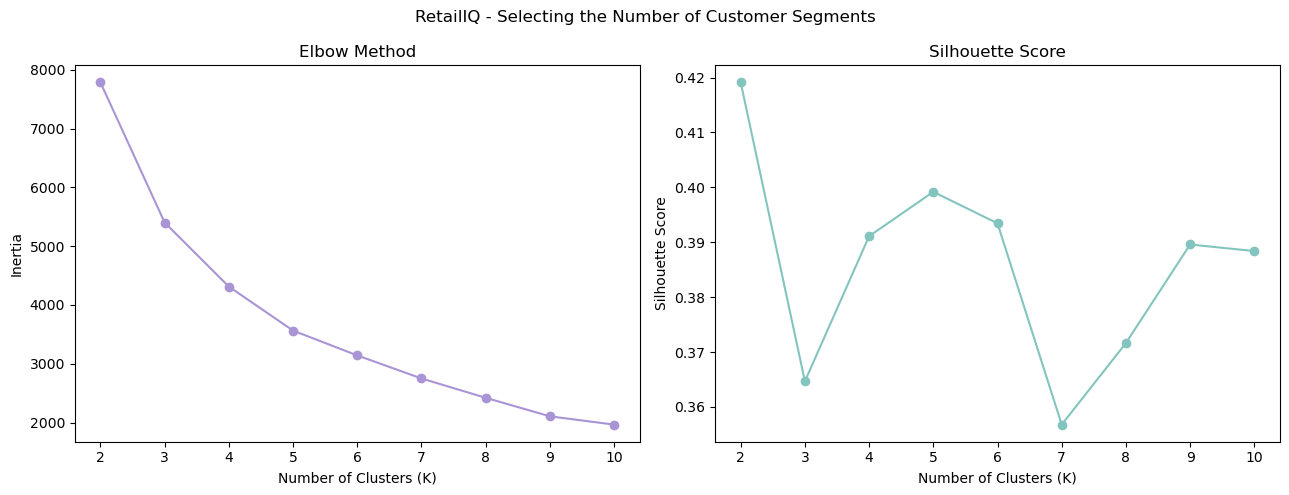

Graph saved: 26_optimal_cluster_selection.png


In [25]:

# Step 5.5: Find a suitable number of clusters

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Test cluster counts from 2 to 10
k_values = range(2, 11)

inertia_values = []
silhouette_values = []

for k in k_values:

    # Create and train the K-Means model
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(rfm_scaled_df)

    # Store inertia for the Elbow Method
    inertia_values.append(kmeans.inertia_)

    # Store Silhouette Score
    silhouette_values.append(
        silhouette_score(rfm_scaled_df, cluster_labels)
    )

# Display the results
cluster_results = pd.DataFrame({
    "Number of Clusters (K)": list(k_values),
    "Inertia": inertia_values,
    "Silhouette Score": silhouette_values
})

display(cluster_results.round(4))

# Plot both evaluation measures
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Elbow Method
axes[0].plot(
    list(k_values),
    inertia_values,
    marker="o",
    color="#A994D6"
)
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(list(k_values))

# Silhouette Score
axes[1].plot(
    list(k_values),
    silhouette_values,
    marker="o",
    color="#83C5BE"
)
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(list(k_values))

plt.suptitle("RetailIQ - Selecting the Number of Customer Segments")
plt.tight_layout()

# Save the graph
plt.savefig(
    os.path.join(graph_folder, "26_optimal_cluster_selection.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved: 26_optimal_cluster_selection.png")

In [26]:

# Step 5.6: Compare the two candidate cluster counts

from sklearn.metrics import (
    davies_bouldin_score,
    calinski_harabasz_score,
    silhouette_score
)

candidate_results = []

for k in [2, 5]:

    # Train K-Means for the selected number of clusters
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(rfm_scaled_df)

    # Calculate clustering evaluation metrics
    candidate_results.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette Score": silhouette_score(rfm_scaled_df, labels),
        "Davies-Bouldin Index": davies_bouldin_score(
            rfm_scaled_df, labels
        ),
        "Calinski-Harabasz Index": calinski_harabasz_score(
            rfm_scaled_df, labels
        )
    })

    # Display the number of customers in each cluster
    print(f"\nCustomer counts for K = {k}:")
    display(
        pd.Series(labels)
        .value_counts()
        .sort_index()
        .rename_axis("Cluster")
        .to_frame("Customer Count")
    )

# Display the comparison
candidate_comparison = pd.DataFrame(candidate_results)

print("\nClustering metric comparison:")
display(candidate_comparison.round(4))


Customer counts for K = 2:


,Customer Count
Cluster,
0,1104
1,3072



Customer counts for K = 5:


,Customer Count
Cluster,
0,759
1,1369
2,324
3,1248
4,476



Clustering metric comparison:


,K,Inertia,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,2,7787.7164,0.4191,1.0859,2540.6650
1,5,3564.0802,0.3992,0.9688,2622.5918


In [27]:

# Step 5.8: Train the final candidate K-Means model

# Create the K-Means model with five clusters
kmeans_model = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

# Assign a cluster to each customera
rfm["Cluster"] = kmeans_model.fit_predict(rfm_scaled_df)

# Display the first few customer records with their cluster labels
display(rfm.head(10))

# Check the number of customers in each cluster
print("Number of customers in each cluster:")
display(
    rfm["Cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("Cluster")
    .to_frame("Customer Count")
)

print("\nTotal customers assigned:", rfm["Cluster"].notna().sum())

,customer_id,Recency,Frequency,Monetary,Cluster
0,1000,248,1,1228.72,3
1,1003,89,1,1681.96,1
2,1008,49,1,1546.42,1
3,1009,100,3,4616.63,2
4,1014,318,1,2423.92,3
5,1026,350,1,244.30,3
6,1028,138,1,2328.44,1
7,1029,155,1,357.02,1
8,1031,129,2,2231.42,0
9,1033,333,1,571.06,3


Number of customers in each cluster:


,Customer Count
Cluster,
0,759
1,1369
2,324
3,1248
4,476



Total customers assigned: 4176


In [28]:

# Step 5.9: Calculate RFM statistics for each cluster

# Summarize customer behavior within each cluster
cluster_summary = rfm.groupby("Cluster").agg(
    Customer_Count=("customer_id", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Total_Revenue=("Monetary", "sum")
).round(2)

# Calculate each cluster's percentage of customers and revenue
cluster_summary["Customer_Percentage"] = (
    cluster_summary["Customer_Count"] / len(rfm) * 100
).round(2)

cluster_summary["Revenue_Percentage"] = (
    cluster_summary["Total_Revenue"] / rfm["Monetary"].sum() * 100
).round(2)

# Display the results
display(cluster_summary)

# Identify the cluster with the highest average monetary value
print(
    "\nCluster with highest average monetary value:",
    cluster_summary["Avg_Monetary"].idxmax()
)

# Identify the cluster with the lowest average recency
print(
    "Cluster with most recent average purchases:",
    cluster_summary["Avg_Recency"].idxmin()
)

# Identify the cluster with the highest average frequency
print(
    "Cluster with highest average purchase frequency:",
    cluster_summary["Avg_Frequency"].idxmax()
)

,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue,Customer_Percentage,Revenue_Percentage
Cluster,,,,,,,
0,759,108.19,2.09,2710.23,2057064.89,18.18,20.33
1,1369,91.19,1.00,1423.65,1948977.41,32.78,19.27
2,324,92.80,2.65,7009.33,2271024.09,7.76,22.45
3,1248,281.64,1.03,1319.18,1646336.12,29.89,16.27
4,476,207.63,1.09,4606.65,2192766.55,11.40,21.68



Cluster with highest average monetary value: 2
Cluster with most recent average purchases: 1
Cluster with highest average purchase frequency: 2


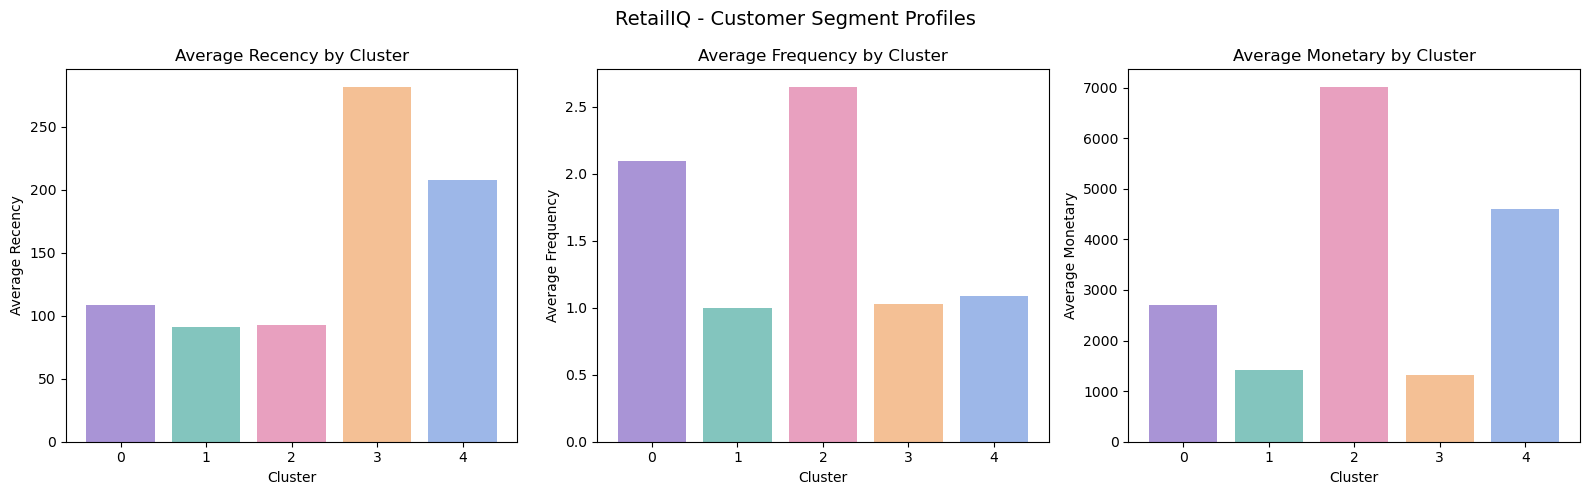

Graph saved: 27_customer_segment_profiles.png


In [30]:

# Step 5.10: Visualize RFM profiles for all five clusters

# Calculate average RFM values for each cluster
cluster_rfm_means = rfm.groupby("Cluster")[
    ["Recency", "Frequency", "Monetary"]
].mean()

# Plot the cluster profiles
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

colors = ["#A994D6", "#83C5BE", "#E8A0BF", "#F4C095", "#9DB7E8"]

for i, column in enumerate(["Recency", "Frequency", "Monetary"]):

    axes[i].bar(
        cluster_rfm_means.index.astype(str),
        cluster_rfm_means[column],
        color=colors
    )

    axes[i].set_title(f"Average {column} by Cluster")
    axes[i].set_xlabel("Cluster")
    axes[i].set_ylabel(f"Average {column}")

plt.suptitle("RetailIQ - Customer Segment Profiles", fontsize=14)
plt.tight_layout()

# Save the graph
plt.savefig(
    os.path.join(graph_folder, "27_customer_segment_profiles.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved: 27_customer_segment_profiles.png")

,Cluster,Customer_Count,Total_Revenue,Revenue_Percentage,Avg_Revenue_Per_Customer
2,2,324,2271024.09,22.45,7009.33
4,4,476,2192766.55,21.68,4606.65
0,0,759,2057064.89,20.33,2710.23
1,1,1369,1948977.41,19.27,1423.65
3,3,1248,1646336.12,16.27,1319.18


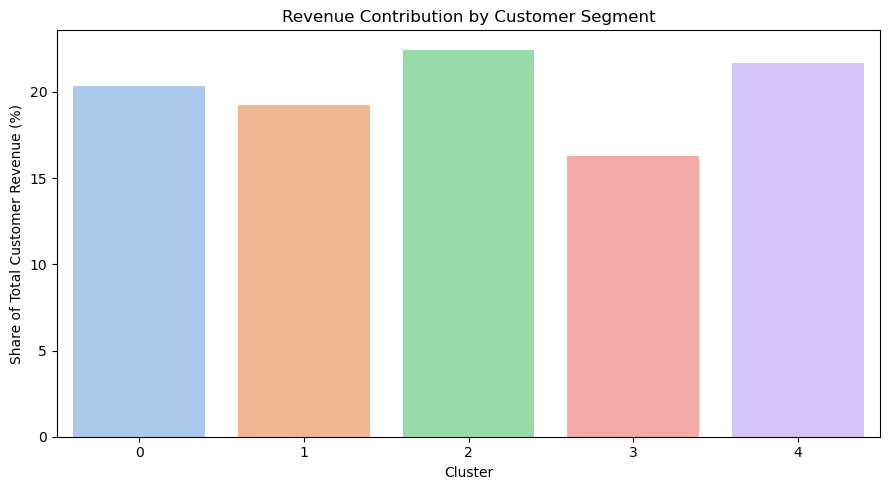

Graph saved: 28_cluster_revenue_contribution.png


In [31]:

# Step 5.11: Analyze revenue contribution by customer segment

# Calculate total revenue and customer count for each cluster
cluster_revenue = rfm.groupby("Cluster").agg(
    Customer_Count=("customer_id", "count"),
    Total_Revenue=("Monetary", "sum")
).reset_index()

# Calculate each cluster's share of total revenue
total_revenue = rfm["Monetary"].sum()

cluster_revenue["Revenue_Percentage"] = (
    cluster_revenue["Total_Revenue"] / total_revenue * 100
)

# Calculate average revenue per customer
cluster_revenue["Avg_Revenue_Per_Customer"] = (
    cluster_revenue["Total_Revenue"] /
    cluster_revenue["Customer_Count"]
)

# Sort clusters by revenue contribution
cluster_revenue = cluster_revenue.sort_values(
    "Revenue_Percentage",
    ascending=False
)

# Display the results
display(cluster_revenue.round(2))

# Plot revenue contribution
plt.figure(figsize=(9, 5))

sns.barplot(
    data=cluster_revenue,
    x="Cluster",
    y="Revenue_Percentage",
    hue="Cluster",
    palette="pastel",
    legend=False
)

plt.title("Revenue Contribution by Customer Segment")
plt.xlabel("Cluster")
plt.ylabel("Share of Total Customer Revenue (%)")
plt.tight_layout()

# Save the graph
plt.savefig(
    os.path.join(graph_folder, "28_cluster_revenue_contribution.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved: 28_cluster_revenue_contribution.png")

In [32]:

# Step 5.12: Validate customer segmentation

# Check total customers and unique customer IDs
print("Total RFM records:", len(rfm))
print("Unique customer IDs:", rfm["customer_id"].nunique())

# Check whether any cluster assignments are missing
print("Missing cluster assignments:", rfm["Cluster"].isna().sum())

# Check the number of clusters
print("Number of clusters:", rfm["Cluster"].nunique())

# Check that cluster customer counts add up correctly
print("\nCustomers per cluster:")
display(
    rfm.groupby("Cluster").size().to_frame("Customer_Count")
)

print(
    "\nDo cluster counts equal total customers?",
    rfm.groupby("Cluster").size().sum() == len(rfm)
)

# Check that revenue percentages add up to 100%
print(
    "\nTotal revenue percentage:",
    round(cluster_revenue["Revenue_Percentage"].sum(), 2), "%"
)

Total RFM records: 4176
Unique customer IDs: 4176
Missing cluster assignments: 0
Number of clusters: 5

Customers per cluster:


,Customer_Count
Cluster,
0,759
1,1369
2,324
3,1248
4,476



Do cluster counts equal total customers? True

Total revenue percentage: 100.0 %


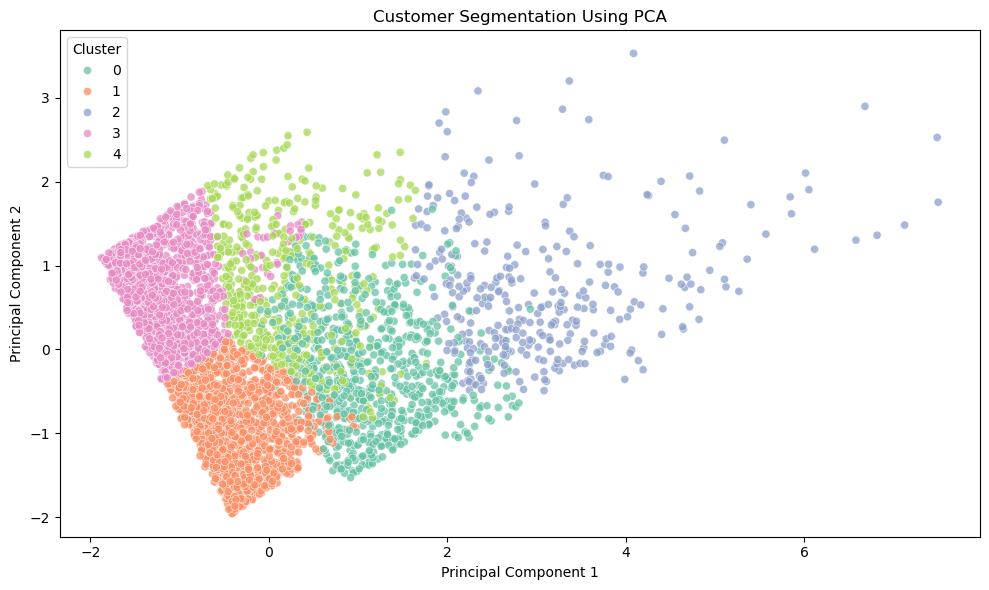

Variance explained by two components: 85.32 %
Graph saved: 29_rfm_clusters_pca.png


In [65]:

# Step 5.13: Visualize customer clusters using PCA

from sklearn.decomposition import PCA

# Reduce the three RFM features to two dimensions for visualization
pca = PCA(n_components=2)
rfm_pca = pca.fit_transform(rfm_scaled_df)

# Store the two PCA components and cluster labels
pca_df = pd.DataFrame({
    "PCA1": rfm_pca[:, 0],
    "PCA2": rfm_pca[:, 1],
    "Cluster": rfm["Cluster"].values
})

# Plot the customer clusters
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=pca_df,
    x="PCA1",
    y="PCA2",
    hue="Cluster",
    palette="Set2",
    s=35,
    alpha=0.75
)

plt.title("Customer Segmentation Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.tight_layout()

# Save the graph
plt.savefig(
    os.path.join(graph_folder, "29_rfm_clusters_pca.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Show how much information the two components retain
print(
    "Variance explained by two components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2), "%"
)

print("Graph saved: 29_rfm_clusters_pca.png")

In [33]:
# Step 5.14: Assign business names to customer segments

# Give each cluster a meaningful name based on its RFM profile
segment_names = {
    0: "Repeat Customers",
    1: "Recent One-Time Customers",
    2: "High-Value Frequent Customers",
    3: "Inactive / At-Risk Customers",
    4: "High-Spending At-Risk Customers"
}

# Add the segment names to the RFM table
rfm["Customer_Segment"] = rfm["Cluster"].map(segment_names)

# Display customer counts and revenue by segment
segment_summary = rfm.groupby("Customer_Segment").agg(
    Customer_Count=("customer_id", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Total_Revenue=("Monetary", "sum")
).round(2)

display(segment_summary)

,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue
Customer_Segment,,,,,
High-Spending At-Risk Customers,476,207.63,1.09,4606.65,2192766.55
High-Value Frequent Customers,324,92.80,2.65,7009.33,2271024.09
Inactive / At-Risk Customers,1248,281.64,1.03,1319.18,1646336.12
Recent One-Time Customers,1369,91.19,1.00,1423.65,1948977.41
Repeat Customers,759,108.19,2.09,2710.23,2057064.89


In [34]:
# Step 5.15: Export customer segmentation results

# Save the RFM table with cluster numbers and business segment names
rfm.to_csv("RetailIQ_Customer_Segments.csv", index=False)

# Save the segment-level summary
segment_summary.to_csv("RetailIQ_Segment_Summary.csv")

print("Customer segmentation saved successfully!")
print("File 1: RetailIQ_Customer_Segments.csv")
print("File 2: RetailIQ_Segment_Summary.csv")

Customer segmentation saved successfully!
File 1: RetailIQ_Customer_Segments.csv
File 2: RetailIQ_Segment_Summary.csv


In [68]:
# Step 5.16: Evaluate the final K-Means model

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Calculate clustering evaluation metrics
silhouette = silhouette_score(rfm_scaled_df, rfm["Cluster"])
db_index = davies_bouldin_score(rfm_scaled_df, rfm["Cluster"])
ch_index = calinski_harabasz_score(rfm_scaled_df, rfm["Cluster"])

# Display the results
print("Number of clusters:", rfm["Cluster"].nunique())
print("Silhouette Score:", round(silhouette, 4))
print("Davies-Bouldin Index:", round(db_index, 4))
print("Calinski-Harabasz Index:", round(ch_index, 4))

Number of clusters: 5
Silhouette Score: 0.3992
Davies-Bouldin Index: 0.9688
Calinski-Harabasz Index: 2622.5918


In [69]:
# Step 6.1: Implement Agglomerative Clustering

from sklearn.cluster import AgglomerativeClustering

# Create the model with five customer clusters
agg_model = AgglomerativeClustering(n_clusters=5)

# Assign each customer to a cluster
rfm["Agg_Cluster"] = agg_model.fit_predict(rfm_scaled_df)

# Display the number of customers in each cluster
print("Agglomerative Clustering - Customer Counts:")
display(rfm["Agg_Cluster"].value_counts().sort_index())

# Display the first few customer assignments
display(rfm[["customer_id", "Cluster", "Agg_Cluster"]].head(10))

Agglomerative Clustering - Customer Counts:


Agg_Cluster
0     494
1    1363
2    1015
3     665
4     639
Name: count, dtype: int64

,customer_id,Cluster,Agg_Cluster
0,1000,3,1
1,1003,1,2
2,1008,1,2
3,1009,2,0
4,1014,3,4
5,1026,3,1
6,1028,1,2
7,1029,1,1
8,1031,0,3
9,1033,3,1


In [70]:
# Step 6.2: Evaluate Agglomerative Clustering

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Calculate the evaluation metrics
agg_silhouette = silhouette_score(
    rfm_scaled_df, rfm["Agg_Cluster"]
)

agg_db = davies_bouldin_score(
    rfm_scaled_df, rfm["Agg_Cluster"]
)

agg_ch = calinski_harabasz_score(
    rfm_scaled_df, rfm["Agg_Cluster"]
)

# Display the results
print("Model: Agglomerative Clustering")
print("Number of clusters:", rfm["Agg_Cluster"].nunique())
print("Silhouette Score:", round(agg_silhouette, 4))
print("Davies-Bouldin Index:", round(agg_db, 4))
print("Calinski-Harabasz Index:", round(agg_ch, 4))

Model: Agglomerative Clustering
Number of clusters: 5
Silhouette Score: 0.3444
Davies-Bouldin Index: 1.1261
Calinski-Harabasz Index: 2220.3403


In [71]:
# Step 6.3: Compare all baseline and final models

model_comparison = pd.DataFrame({
    "Model": [
        "K-Means (K=2)",
        "K-Means (K=5)",
        "Agglomerative Clustering (K=5)"
    ],
    "Silhouette_Score": [
        0.4191, 0.3992, agg_silhouette
    ],
    "Davies_Bouldin_Index": [
        1.0859, 0.9688, agg_db
    ],
    "Calinski_Harabasz_Index": [
        2540.6650, 2622.5918, agg_ch
    ]
})

# Display the comparison
display(model_comparison.round(4))

# Save the comparison results
model_comparison.to_csv(
    "RetailIQ_Model_Comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

,Model,Silhouette_Score,Davies_Bouldin_Index,Calinski_Harabasz_Index
0,K-Means (K=2),0.4191,1.0859,2540.6650
1,K-Means (K=5),0.3992,0.9688,2622.5918
2,Agglomerative Clustering (K=5),0.3444,1.1261,2220.3403


Model comparison saved successfully!


In [72]:
# Step 6.4: Check customer coverage

# Count all unique customers in the dataset
total_customers = df_clean["customer_id"].nunique()

# Count customers who made at least one purchase
purchasing_customers = rfm["customer_id"].nunique()

# Calculate the number of customers without a recorded purchase
non_purchasing_customers = total_customers - purchasing_customers

# Display the results
print("Total unique customers:", total_customers)
print("Customers who purchased:", purchasing_customers)
print("Customers without a recorded purchase:", non_purchasing_customers)

print(
    "Percentage of customers covered by RFM:",
    round(purchasing_customers / total_customers * 100, 2), "%"
)

Total unique customers: 8442
Customers who purchased: 4176
Customers without a recorded purchase: 4266
Percentage of customers covered by RFM: 49.47 %


In [73]:
# Step 6.5: Inspect potential customer behavior features

# Select useful session-level behavior columns
behavior_columns = [
    "customer_id",
    "pages_viewed",
    "time_on_site_sec",
    "added_to_cart",
    "purchased",
    "revenue"
]

# Display the selected columns
display(df_clean[behavior_columns].head())

# Check the data types and missing values
print("\nColumn information:")
display(df_clean[behavior_columns].info())

,customer_id,pages_viewed,time_on_site_sec,added_to_cart,purchased,revenue
0,1803,21,965,1,0,0.00
1,7964,21,1158,0,0,0.00
2,6890,19,710,1,0,0.00
3,4949,19,1674,1,1,2410.23
4,4896,13,427,1,0,0.00



Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       25000 non-null  int64  
 1   pages_viewed      25000 non-null  int64  
 2   time_on_site_sec  25000 non-null  int64  
 3   added_to_cart     25000 non-null  int64  
 4   purchased         25000 non-null  int64  
 5   revenue           25000 non-null  float64
dtypes: float64(1), int64(5)
memory usage: 1.1 MB


None

In [74]:

# Step 6.6: Create customer-level behavior features

# Aggregate session behavior for each customer
behavior_features = df_clean.groupby("customer_id").agg(
    Avg_Pages_Viewed=("pages_viewed", "mean"),
    Avg_Time_On_Site=("time_on_site_sec", "mean"),
    Cart_Addition_Rate=("added_to_cart", "mean")
).reset_index()

# Round values for easier viewing
behavior_features = behavior_features.round(3)

# Display the first few customers
display(behavior_features.head(10))

# Check the number of customers and features
print("Total customers:", len(behavior_features))
print("Number of behavior features:", len(behavior_features.columns) - 1)

,customer_id,Avg_Pages_Viewed,Avg_Time_On_Site,Cart_Addition_Rate
0,1000,17.500,1014.000,1.000
1,1001,15.000,996.000,0.000
2,1002,8.333,313.667,0.667
3,1003,5.667,695.333,0.333
4,1004,12.333,923.667,0.333
5,1005,14.000,312.333,0.667
6,1006,13.500,1145.000,0.500
7,1007,22.000,557.000,0.000
8,1008,9.800,829.200,0.400
9,1009,11.000,806.600,1.000


Total customers: 8442
Number of behavior features: 3


In [75]:
# Step 6.7: Verify behavior feature values

print("Column names:")
print(behavior_features.columns.tolist())

print("\nFirst 5 rows:")
print(behavior_features.head().to_string(index=False))

print("\nFeature summary:")
display(behavior_features[
    ["Avg_Pages_Viewed", "Avg_Time_On_Site", "Cart_Addition_Rate"]
].describe().round(3))

Column names:
['customer_id', 'Avg_Pages_Viewed', 'Avg_Time_On_Site', 'Cart_Addition_Rate']

First 5 rows:
 customer_id  Avg_Pages_Viewed  Avg_Time_On_Site  Cart_Addition_Rate
        1000            17.500          1014.000               1.000
        1001            15.000           996.000               0.000
        1002             8.333           313.667               0.667
        1003             5.667           695.333               0.333
        1004            12.333           923.667               0.333

Feature summary:


,Avg_Pages_Viewed,Avg_Time_On_Site,Cart_Addition_Rate
count,8442.000,8442.000,8442.000
mean,12.540,906.731,0.643
std,4.648,354.852,0.327
min,1.000,10.000,0.000
25%,9.500,672.271,0.500
50%,12.500,905.775,0.667
75%,15.667,1140.188,1.000
max,24.000,1794.000,1.000


In [76]:
# Step 6.8: Prepare the same customers for both feature sets

# Select behavior features only for customers included in RFM
behavior_rfm = rfm[["customer_id"]].merge(
    behavior_features,
    on="customer_id",
    how="left"
)

# Select the three behavior features for clustering
behavior_feature_columns = [
    "Avg_Pages_Viewed",
    "Avg_Time_On_Site",
    "Cart_Addition_Rate"
]

behavior_rfm_features = behavior_rfm[behavior_feature_columns]

# Check the data
print("RFM customers:", len(rfm))
print("Behavior-feature customers:", len(behavior_rfm))
print("Missing behavior values:", behavior_rfm_features.isna().sum().sum())

display(behavior_rfm.head())

RFM customers: 4176
Behavior-feature customers: 4176
Missing behavior values: 0


,customer_id,Avg_Pages_Viewed,Avg_Time_On_Site,Cart_Addition_Rate
0,1000,17.500,1014.000,1.000
1,1003,5.667,695.333,0.333
2,1008,9.800,829.200,0.400
3,1009,11.000,806.600,1.000
4,1014,11.750,985.000,0.500


In [77]:
# Step 6.9: Standardize behavior features

from sklearn.preprocessing import StandardScaler

# Scale the three customer behavior features
behavior_scaler = StandardScaler()

behavior_scaled = behavior_scaler.fit_transform(
    behavior_rfm_features
)

# Convert the scaled values back into a DataFrame
behavior_scaled_df = pd.DataFrame(
    behavior_scaled,
    columns=behavior_feature_columns
)

# Check the scaled feature values
display(behavior_scaled_df.describe().round(3))

,Avg_Pages_Viewed,Avg_Time_On_Site,Cart_Addition_Rate
count,4176.000,4176.000,4176.000
mean,-0.000,-0.000,-0.000
std,1.000,1.000,1.000
min,-2.772,-2.823,-2.665
25%,-0.668,-0.672,-0.789
50%,0.014,-0.018,-0.005
75%,0.674,0.659,1.090
max,2.758,2.758,1.090


In [78]:
# Step 6.10: Apply K-Means to behavior features

from sklearn.cluster import KMeans

# Create a K-Means model with five clusters
behavior_kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

# Assign customers to behavior-based clusters
behavior_clusters = behavior_kmeans.fit_predict(
    behavior_scaled_df
)

# Store the new assignments separately
behavior_rfm["Behavior_Cluster"] = behavior_clusters

# Display the number of customers in each cluster
print("Behavior-Based K-Means - Customer Counts:")
display(
    behavior_rfm["Behavior_Cluster"]
    .value_counts()
    .sort_index()
)

# Show sample customer assignments
display(behavior_rfm.head(10))

Behavior-Based K-Means - Customer Counts:


Behavior_Cluster
0    870
1    624
2    911
3    995
4    776
Name: count, dtype: int64

,customer_id,Avg_Pages_Viewed,Avg_Time_On_Site,Cart_Addition_Rate,Behavior_Cluster
0,1000,17.500,1014.000,1.000,4
1,1003,5.667,695.333,0.333,3
2,1008,9.800,829.200,0.400,3
3,1009,11.000,806.600,1.000,0
4,1014,11.750,985.000,0.500,3
5,1026,16.333,603.000,1.000,0
6,1028,11.400,956.600,0.800,3
7,1029,17.000,272.000,1.000,0
8,1031,19.250,1274.000,1.000,4
9,1033,17.000,480.200,0.400,2


In [79]:

# Step 6.11: Evaluate behavior-based K-Means

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Calculate clustering evaluation metrics
behavior_silhouette = silhouette_score(
    behavior_scaled_df,
    behavior_rfm["Behavior_Cluster"]
)

behavior_db = davies_bouldin_score(
    behavior_scaled_df,
    behavior_rfm["Behavior_Cluster"]
)

behavior_ch = calinski_harabasz_score(
    behavior_scaled_df,
    behavior_rfm["Behavior_Cluster"]
)

# Display the results
print("Model: Behavior-Based K-Means (K=5)")
print("Silhouette Score:", round(behavior_silhouette, 4))
print("Davies-Bouldin Index:", round(behavior_db, 4))
print("Calinski-Harabasz Index:", round(behavior_ch, 4))

Model: Behavior-Based K-Means (K=5)
Silhouette Score: 0.2364
Davies-Bouldin Index: 1.2053
Calinski-Harabasz Index: 1348.5334


In [80]:

# Step 6.12: Compare RFM and behavior feature sets

feature_comparison = pd.DataFrame({
    "Feature_Set": [
        "RFM Features",
        "Behavior Features"
    ],
    "Model": [
        "K-Means (K=5)",
        "K-Means (K=5)"
    ],
    "Silhouette_Score": [
        silhouette,
        behavior_silhouette
    ],
    "Davies_Bouldin_Index": [
        db_index,
        behavior_db
    ],
    "Calinski_Harabasz_Index": [
        ch_index,
        behavior_ch
    ]
})

# Display the comparison results
display(feature_comparison.round(4))

# Save the results
feature_comparison.to_csv(
    "RetailIQ_Feature_Set_Comparison.csv",
    index=False
)

print("Feature-set comparison saved successfully!")

,Feature_Set,Model,Silhouette_Score,Davies_Bouldin_Index,Calinski_Harabasz_Index
0,RFM Features,K-Means (K=5),0.3992,0.9688,2622.5918
1,Behavior Features,K-Means (K=5),0.2364,1.2053,1348.5334


Feature-set comparison saved successfully!


In [81]:

# Step 7.1: Create business recommendations for each segment

# Define a business strategy for each customer segment
recommendations = {
    "High-Value Frequent Customers":
        "Offer loyalty rewards and personalized product recommendations",

    "High-Spending At-Risk Customers":
        "Send personalized win-back offers and product reminders",

    "Inactive / At-Risk Customers":
        "Run re-engagement campaigns and test targeted incentives",

    "Repeat Customers":
        "Encourage repeat purchases with bundles and relevant cross-selling",

    "Recent One-Time Customers":
        "Send follow-up recommendations and incentives for a second purchase"
}

# Add recommendations to the segment summary
segment_summary["Business_Recommendation"] = (
    segment_summary.index.map(recommendations)
)

# Display the final segment strategies
display(segment_summary)

# Save the recommendations
segment_summary.to_csv("RetailIQ_Business_Recommendations.csv")

print("Business recommendations saved successfully!")

,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue,Business_Recommendation
Customer_Segment,,,,,,
High-Spending At-Risk Customers,476,207.63,1.09,4606.65,2192766.55,Send personalized win-back offers and product ...
High-Value Frequent Customers,324,92.80,2.65,7009.33,2271024.09,Offer loyalty rewards and personalized product...
Inactive / At-Risk Customers,1248,281.64,1.03,1319.18,1646336.12,Run re-engagement campaigns and test targeted ...
Recent One-Time Customers,1369,91.19,1.00,1423.65,1948977.41,Send follow-up recommendations and incentives ...
Repeat Customers,759,108.19,2.09,2710.23,2057064.89,Encourage repeat purchases with bundles and re...


Business recommendations saved successfully!


In [82]:

# Step 7.2: Save the final customer segmentation results

# Keep the important customer-level segmentation columns
final_segments = rfm[
    [
        "customer_id",
        "Recency",
        "Frequency",
        "Monetary",
        "Cluster",
        "Customer_Segment"
    ]
].copy()

# Save the final results
final_segments.to_csv("RetailIQ_Customer_Segments.csv", index=False)

print("Final customer segmentation saved successfully!")
print("Total customers segmented:", len(final_segments))
print("Number of segments:", final_segments["Customer_Segment"].nunique())

Final customer segmentation saved successfully!
Total customers segmented: 4176
Number of segments: 5


In [83]:

# Step 7.3: Check whether our important project files exist

required_files = [
    "RetailIQ_Customer_Segments.csv",
    "RetailIQ_Segment_Summary.csv",
    "RetailIQ_Business_Recommendations.csv",
    "RetailIQ_Model_Comparison.csv",
    "RetailIQ_Feature_Set_Comparison.csv"
]

for file in required_files:
    if os.path.exists(file):
        print(file, "- Available")
    else:
        print(file, "- Missing")

RetailIQ_Customer_Segments.csv - Available
RetailIQ_Segment_Summary.csv - Available
RetailIQ_Business_Recommendations.csv - Available
RetailIQ_Model_Comparison.csv - Available
RetailIQ_Feature_Set_Comparison.csv - Available


In [84]:

# Step 1: Final validation of the dataset

print("DATASET VALIDATION")
print("------------------")

# Check dataset dimensions
print("Dataset shape:", df_clean.shape)

# Check missing values
print("Total missing values:", df_clean.isnull().sum().sum())

# Check duplicate rows
print("Duplicate rows:", df_clean.duplicated().sum())

# Check date data type
print("Visit date data type:", df_clean["visit_date"].dtype)

# Check purchase counts
print("\nPurchase counts:")
print(df_clean["purchased"].value_counts().sort_index())

# Check whether purchase values are only 0 and 1
print("\nValid purchase values:", 
      set(df_clean["purchased"].unique()) == {0, 1})

# Check total unique customers and sessions
print("\nUnique customers:", df_clean["customer_id"].nunique())
print("Unique sessions:", df_clean["session_id"].nunique())

DATASET VALIDATION
------------------
Dataset shape: (25000, 31)
Total missing values: 0
Duplicate rows: 0
Visit date data type: datetime64[ns]

Purchase counts:
purchased
0    19384
1     5616
Name: count, dtype: int64

Valid purchase values: True

Unique customers: 8442
Unique sessions: 25000


In [85]:

# Step 2: Inspect all columns in the cleaned dataset

print("Total columns:", len(df_clean.columns))

for column in df_clean.columns:
    print(column)

Total columns: 31
customer_id
session_id
visit_date
device_type
user_type
marketing_channel
product_id
product_category
unit_price
quantity
discount_percent
discount_amount
revenue
pages_viewed
time_on_site_sec
added_to_cart
purchased
cart_abandoned
rating
review_text
review_helpful_votes
payment_method
visit_day
visit_month
visit_weekday
visit_season
session_duration_bucket
revenue_normalized
location
month
discount_group


In [86]:

# Step 3: Validate final RFM customer segmentation

print("RFM SEGMENTATION VALIDATION")
print("---------------------------")

print("Total RFM customers:", len(rfm))
print("Unique customer IDs:", rfm["customer_id"].nunique())
print("Missing cluster assignments:", rfm["Cluster"].isnull().sum())
print("Number of clusters:", rfm["Cluster"].nunique())
print("Missing segment names:", rfm["Customer_Segment"].isnull().sum())

print("\nCustomers in each segment:")
print(rfm["Customer_Segment"].value_counts())

print("\nTotal RFM revenue:", round(rfm["Monetary"].sum(), 2))
print("Total segment revenue:", round(
    rfm.groupby("Customer_Segment")["Monetary"].sum().sum(), 2
))

RFM SEGMENTATION VALIDATION
---------------------------
Total RFM customers: 4176
Unique customer IDs: 4176
Missing cluster assignments: 0
Number of clusters: 5
Missing segment names: 0

Customers in each segment:
Customer_Segment
Recent One-Time Customers          1369
Inactive / At-Risk Customers       1248
Repeat Customers                    759
High-Spending At-Risk Customers     476
High-Value Frequent Customers       324
Name: count, dtype: int64

Total RFM revenue: 10116169.06
Total segment revenue: 10116169.06


In [87]:

# Step 4: Validate clustering model comparison

print("MODEL COMPARISON VALIDATION")
print("---------------------------")

display(model_comparison)

print("\nChecking metric values...")

print(
    "All Silhouette scores present:",
    model_comparison["Silhouette_Score"].notnull().all()
)

print(
    "All Davies-Bouldin values present:",
    model_comparison["Davies_Bouldin_Index"].notnull().all()
)

print(
    "All Calinski-Harabasz values present:",
    model_comparison["Calinski_Harabasz_Index"].notnull().all()
)

print("\nBest Silhouette Score:")
print(
    model_comparison.loc[
        model_comparison["Silhouette_Score"].idxmax(), "Model"
    ]
)

print("\nLowest Davies-Bouldin Index:")
print(
    model_comparison.loc[
        model_comparison["Davies_Bouldin_Index"].idxmin(), "Model"
    ]
)

print("\nHighest Calinski-Harabasz Index:")
print(
    model_comparison.loc[
        model_comparison["Calinski_Harabasz_Index"].idxmax(), "Model"
    ]
)

MODEL COMPARISON VALIDATION
---------------------------


,Model,Silhouette_Score,Davies_Bouldin_Index,Calinski_Harabasz_Index
0,K-Means (K=2),0.41910,1.0859,2540.665000
1,K-Means (K=5),0.39920,0.9688,2622.591800
2,Agglomerative Clustering (K=5),0.34436,1.1261,2220.340299



Checking metric values...
All Silhouette scores present: True
All Davies-Bouldin values present: True
All Calinski-Harabasz values present: True

Best Silhouette Score:
K-Means (K=2)

Lowest Davies-Bouldin Index:
K-Means (K=5)

Highest Calinski-Harabasz Index:
K-Means (K=5)


In [88]:

# Step 5: Validate feature-set comparison

print("FEATURE-SET COMPARISON")
print("----------------------")

display(feature_comparison)

print("\nChecking metric values...")

print(
    "All Silhouette scores present:",
    feature_comparison["Silhouette_Score"].notnull().all()
)

print(
    "All Davies-Bouldin values present:",
    feature_comparison["Davies_Bouldin_Index"].notnull().all()
)

print(
    "All Calinski-Harabasz values present:",
    feature_comparison["Calinski_Harabasz_Index"].notnull().all()
)

print("\nBest feature set by Silhouette Score:")
print(
    feature_comparison.loc[
        feature_comparison["Silhouette_Score"].idxmax(),
        "Feature_Set"
    ]
)

FEATURE-SET COMPARISON
----------------------


,Feature_Set,Model,Silhouette_Score,Davies_Bouldin_Index,Calinski_Harabasz_Index
0,RFM Features,K-Means (K=5),0.399189,0.968770,2622.591796
1,Behavior Features,K-Means (K=5),0.236375,1.205346,1348.533442



Checking metric values...
All Silhouette scores present: True
All Davies-Bouldin values present: True
All Calinski-Harabasz values present: True

Best feature set by Silhouette Score:
RFM Features


In [89]:

# Step 6: Validate saved project output files

files_to_check = {
    "RetailIQ_Customer_Segments.csv": 4176,
    "RetailIQ_Segment_Summary.csv": 5,
    "RetailIQ_Business_Recommendations.csv": 5,
    "RetailIQ_Model_Comparison.csv": 3,
    "RetailIQ_Feature_Set_Comparison.csv": 2
}

print("SAVED FILE VALIDATION")
print("---------------------")

for file, expected_rows in files_to_check.items():
    if os.path.exists(file):
        saved_data = pd.read_csv(file)

        print(f"\nFile: {file}")
        print("Rows:", len(saved_data))
        print("Expected rows:", expected_rows)
        print("Row count correct:", len(saved_data) == expected_rows)
    else:
        print(f"\nFile: {file} - MISSING")

SAVED FILE VALIDATION
---------------------

File: RetailIQ_Customer_Segments.csv
Rows: 4176
Expected rows: 4176
Row count correct: True

File: RetailIQ_Segment_Summary.csv
Rows: 5
Expected rows: 5
Row count correct: True

File: RetailIQ_Business_Recommendations.csv
Rows: 5
Expected rows: 5
Row count correct: True

File: RetailIQ_Model_Comparison.csv
Rows: 3
Expected rows: 3
Row count correct: True

File: RetailIQ_Feature_Set_Comparison.csv
Rows: 2
Expected rows: 2
Row count correct: True


In [90]:

# Step 7: Check the saved visualization files

graph_folder = "RetailIQ_Graphs"

if os.path.exists(graph_folder):
    graph_files = [
        file for file in os.listdir(graph_folder)
        if file.lower().endswith((".png", ".jpg", ".jpeg"))
    ]

    print("GRAPH VALIDATION")
    print("----------------")
    print("Graph folder:", graph_folder)
    print("Total saved graphs:", len(graph_files))

    for file in sorted(graph_files):
        print(file)
else:
    print("Graph folder not found:", graph_folder)

GRAPH VALIDATION
----------------
Graph folder: RetailIQ_Graphs
Total saved graphs: 30
01_example_graph.png
01_overall_business_metrics.png
02_monthly_revenue_trend.png
03_monthly_purchase_trend.png
04_category_revenue.png
05_marketing_channel_performance.png
06_device_purchase_behavior.png
07_customer_type_purchase_rate.png
08_shopping_journey_funnel.png
09_numerical_correlation_heatmap.png
10_discount_vs_revenue.png
11_session_duration_distribution.png
12_session_duration_by_purchase.png
13_category_purchase_counts.png
14_marketing_channel_conversion_rate.png
15_purchase_revenue_boxplot.png
16_pages_viewed_by_purchase_outcome.png
17_seasonal_purchase_rate.png
18_univariate_numerical_distributions.png
19_categorical_variable_distributions.png
20_shopping_behavior_distributions.png
21_pages_vs_time_by_purchase.png
22_discount_vs_purchase_rate.png
23_customer_device_purchase_heatmap.png
24_channel_customer_purchase_heatmap.png
25_rfm_distributions.png
26_optimal_cluster_selection.png
27

In [91]:
%pip show streamlit

Name: streamlit
Version: 1.51.0
Summary: A faster way to build and share data apps
Home-page: https://streamlit.io
Author: Snowflake Inc
Author-email: hello@streamlit.io
License: Apache License 2.0
Location: C:\Users\vishu\anaconda3\Lib\site-packages
Requires: altair, blinker, cachetools, click, gitpython, numpy, packaging, pandas, pillow, protobuf, pyarrow, requests, tenacity, toml, tornado, typing-extensions, watchdog
Required-by: 
Note: you may need to restart the kernel to use updated packages.


In [4]:
print([name for name in globals() if name.startswith("df")])

['df']


In [20]:
import os

In [22]:
import os

graph_folder = "RetailIQ_Graphs"
os.makedirs(graph_folder, exist_ok=True)

print("Graph folder is ready:", graph_folder)

Graph folder is ready: RetailIQ_Graphs


In [35]:
# Verify both exported CSV files
customer_segments_check = pd.read_csv("RetailIQ_Customer_Segments.csv")
segment_summary_check = pd.read_csv("RetailIQ_Segment_Summary.csv")

print("Customer Segments Shape:", customer_segments_check.shape)
print("Segment Summary Shape:", segment_summary_check.shape)

print("\nCustomer Segments Preview:")
display(customer_segments_check.head())

print("\nSegment Summary:")
display(segment_summary_check)

Customer Segments Shape: (4176, 6)
Segment Summary Shape: (5, 6)

Customer Segments Preview:


,customer_id,Recency,Frequency,Monetary,Cluster,Customer_Segment
0,1000,248,1,1228.72,3,Inactive / At-Risk Customers
1,1003,89,1,1681.96,1,Recent One-Time Customers
2,1008,49,1,1546.42,1,Recent One-Time Customers
3,1009,100,3,4616.63,2,High-Value Frequent Customers
4,1014,318,1,2423.92,3,Inactive / At-Risk Customers



Segment Summary:


,Customer_Segment,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue
0,High-Spending At-Risk Customers,476,207.63,1.09,4606.65,2192766.55
1,High-Value Frequent Customers,324,92.80,2.65,7009.33,2271024.09
2,Inactive / At-Risk Customers,1248,281.64,1.03,1319.18,1646336.12
3,Recent One-Time Customers,1369,91.19,1.00,1423.65,1948977.41
4,Repeat Customers,759,108.19,2.09,2710.23,2057064.89


In [36]:
print("Total customers in summary:",
      segment_summary_check["Customer_Count"].sum())

print("Total segment revenue:",
      round(segment_summary_check["Total_Revenue"].sum(), 2))

print("Unique customers in CSV:",
      customer_segments_check["customer_id"].nunique())

Total customers in summary: 4176
Total segment revenue: 10116169.06
Unique customers in CSV: 4176


In [37]:
# Step 1: Check outliers using the IQR method

numeric_columns = df_clean.select_dtypes(include="number").columns

outlier_results = []

for column in numeric_columns:
    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (df_clean[column] < lower_bound) |
        (df_clean[column] > upper_bound)
    ).sum()

    outlier_results.append({
        "Column": column,
        "Outlier_Count": outlier_count,
        "Lower_Bound": round(lower_bound, 2),
        "Upper_Bound": round(upper_bound, 2)
    })

outlier_summary = pd.DataFrame(outlier_results)
display(outlier_summary)

,Column,Outlier_Count,Lower_Bound,Upper_Bound
0,customer_id,0,-3487.50,14436.50
1,session_id,0,-12499.50,37498.50
2,device_type,0,-1.50,2.50
3,user_type,0,-1.50,2.50
4,marketing_channel,0,-3.50,8.50
5,product_id,0,-450.00,1350.00
6,product_category,0,-2.50,9.50
7,unit_price,0,-657.21,2149.27
8,quantity,0,-2.00,6.00
9,discount_percent,0,-22.50,37.50


In [38]:
# Step 2: Inspect distributions of key numerical columns

columns_to_check = [
    "unit_price",
    "quantity",
    "discount_percent",
    "discount_amount",
    "revenue",
    "pages_viewed",
    "time_on_site_sec",
    "review_helpful_votes"
]

display(df_clean[columns_to_check].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
unit_price,25000.0,782.32,476.61,50.05,395.22,691.72,1096.84,1999.83
quantity,25000.0,2.49,1.11,1.00,1.00,2.00,3.00,4.00
discount_percent,25000.0,9.00,9.26,0.00,0.00,10.00,15.00,30.00
discount_amount,25000.0,175.00,269.01,0.00,0.00,65.82,240.36,2388.26
revenue,25000.0,404.65,1022.39,0.00,0.00,0.00,0.00,7889.36
pages_viewed,25000.0,12.54,6.93,1.00,7.00,13.00,19.00,24.00
time_on_site_sec,25000.0,903.26,518.68,10.00,453.00,903.00,1355.00,1799.00
review_helpful_votes,25000.0,5.52,12.34,0.00,0.00,0.00,0.00,49.00


In [39]:
# Step 3: Inspect the rows with the highest discount amounts

discount_check = df_clean.nlargest(10, "discount_amount")[
    [
        "unit_price",
        "quantity",
        "discount_percent",
        "discount_amount",
        "purchased",
        "revenue"
    ]
]

display(discount_check)

,unit_price,quantity,discount_percent,discount_amount,purchased,revenue
5203,1990.22,4,30,2388.26,1,5572.62
2070,1988.78,4,30,2386.54,1,5568.58
17159,1971.07,4,30,2365.28,0,0.00
22302,1959.83,4,30,2351.80,0,0.00
12315,1900.48,4,30,2280.58,0,0.00
16660,1895.58,4,30,2274.70,1,5307.62
460,1881.79,4,30,2258.15,1,5269.01
11432,1843.84,4,30,2212.61,0,0.00
23937,1830.95,4,30,2197.14,0,0.00
21219,1813.22,4,30,2175.86,0,0.00


In [40]:
# Step 4: Verify discount amounts against price, quantity, and discount rate

expected_discount = (
    df_clean["unit_price"]
    * df_clean["quantity"]
    * df_clean["discount_percent"] / 100
)

discount_difference = (
    df_clean["discount_amount"] - expected_discount
).abs()

print("Maximum discount difference:",
      round(discount_difference.max(), 2))

print("Rows with difference above 0.02:",
      (discount_difference > 0.02).sum())

Maximum discount difference: 0.01
Rows with difference above 0.02: 0


In [41]:
# Step 5: Verify revenue for purchased sessions

expected_revenue = (
    df_clean["unit_price"] * df_clean["quantity"]
    - df_clean["discount_amount"]
).where(df_clean["purchased"] == 1, 0)

revenue_difference = (
    df_clean["revenue"] - expected_revenue
).abs()

print("Maximum revenue difference:",
      round(revenue_difference.max(), 2))

print("Rows exceeding 0.02 tolerance:",
      (revenue_difference > 0.02).sum())

Maximum revenue difference: 0.01
Rows exceeding 0.02 tolerance: 0


In [42]:
# Step 1: Create a separate copy for outlier handling

rfm_capped = rfm.copy()

print("Original RFM shape:", rfm.shape)
print("Copied RFM shape:", rfm_capped.shape)
print("Original RFM data remains unchanged.")

Original RFM shape: (4176, 6)
Copied RFM shape: (4176, 6)
Original RFM data remains unchanged.


In [43]:
# Step 2: Identify potential outliers in RFM features using IQR

rfm_features = ["Recency", "Frequency", "Monetary"]

for column in rfm_features:
    Q1 = rfm_capped[column].quantile(0.25)
    Q3 = rfm_capped[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (rfm_capped[column] < lower_bound) |
        (rfm_capped[column] > upper_bound)
    ).sum()

    print(f"\n{column}")
    print("Lower bound:", round(lower_bound, 2))
    print("Upper bound:", round(upper_bound, 2))
    print("Potential outliers:", outlier_count)


Recency
Lower bound: -194.5
Upper bound: 521.5
Potential outliers: 0

Frequency
Lower bound: -0.5
Upper bound: 3.5
Potential outliers: 38

Monetary
Lower bound: -2796.84
Upper bound: 7071.56
Potential outliers: 139


In [44]:
# Step 3: Apply IQR capping to Frequency and Monetary

rfm_capped["Frequency"] = rfm_capped["Frequency"].clip(upper=3.5)
rfm_capped["Monetary"] = rfm_capped["Monetary"].clip(upper=7071.56)

print("Original RFM shape:", rfm.shape)
print("Capped RFM shape:", rfm_capped.shape)

print("\nFrequency values capped:",
      (rfm["Frequency"] > 3.5).sum())

print("Monetary values capped:",
      (rfm["Monetary"] > 7071.56).sum())

print("\nOriginal RFM remains unchanged:",
      rfm["Monetary"].max() > rfm_capped["Monetary"].max())

Original RFM shape: (4176, 6)
Capped RFM shape: (4176, 6)

Frequency values capped: 38
Monetary values capped: 139

Original RFM remains unchanged: True


In [45]:
# Step 4: Scale the capped RFM features

from sklearn.preprocessing import StandardScaler

rfm_capped_features = rfm_capped[
    ["Recency", "Frequency", "Monetary"]
]

scaler_capped = StandardScaler()
rfm_capped_scaled = scaler_capped.fit_transform(rfm_capped_features)

rfm_capped_scaled_df = pd.DataFrame(
    rfm_capped_scaled,
    columns=["Recency", "Frequency", "Monetary"]
)

print("Scaled capped RFM shape:", rfm_capped_scaled_df.shape)

print("\nFeature means:")
display(rfm_capped_scaled_df.mean().round(3))

print("\nFeature standard deviations:")
display(rfm_capped_scaled_df.std(ddof=0).round(3))

Scaled capped RFM shape: (4176, 3)

Feature means:


Recency     -0.0
Frequency    0.0
Monetary     0.0
dtype: float64


Feature standard deviations:


Recency      1.0
Frequency    1.0
Monetary     1.0
dtype: float64

In [46]:
# Step 5: Evaluate K-Means after outlier capping

from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

kmeans_capped = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

capped_labels = kmeans_capped.fit_predict(rfm_capped_scaled_df)

print("Capped RFM Clustering Results")
print("Number of clusters:", len(set(capped_labels)))
print("Silhouette Score:",
      round(silhouette_score(rfm_capped_scaled_df, capped_labels), 4))
print("Davies-Bouldin Index:",
      round(davies_bouldin_score(rfm_capped_scaled_df, capped_labels), 4))
print("Calinski-Harabasz Index:",
      round(calinski_harabasz_score(rfm_capped_scaled_df, capped_labels), 4))

Capped RFM Clustering Results
Number of clusters: 5
Silhouette Score: 0.4031
Davies-Bouldin Index: 0.97
Calinski-Harabasz Index: 2838.8029


In [47]:
# Step 6: Compare original and capped cluster sizes

print("Original RFM cluster sizes:")
display(rfm["Cluster"].value_counts().sort_index().to_frame("Customer_Count"))

print("\nCapped RFM cluster sizes:")
display(
    pd.Series(capped_labels, name="Cluster")
    .value_counts()
    .sort_index()
    .to_frame("Customer_Count")
)

Original RFM cluster sizes:


,Customer_Count
Cluster,
0,759
1,1369
2,324
3,1248
4,476



Capped RFM cluster sizes:


,Customer_Count
Cluster,
0,1336
1,685
2,1197
3,503
4,455


In [48]:
# Step 7: Compare customer assignments before and after capping

original_labels = rfm["Cluster"].to_numpy()

comparison = pd.DataFrame({
    "Customer_ID": rfm["customer_id"].to_numpy(),
    "Original_Cluster": original_labels,
    "Capped_Cluster": capped_labels
})

# Cluster numbers can be renamed between models.
# Compare actual customer groupings using the Adjusted Rand Index.
from sklearn.metrics import adjusted_rand_score

ari = adjusted_rand_score(original_labels, capped_labels)

print("Adjusted Rand Index:", round(ari, 4))
print("Same cluster number:", (original_labels == capped_labels).sum())
print("Total customers:", len(comparison))

Adjusted Rand Index: 0.8794
Same cluster number: 37
Total customers: 4176


In [49]:
# Step 8: Create customer profiles for capped clusters

rfm_capped_profile = rfm_capped.copy()
rfm_capped_profile["Cluster"] = capped_labels

capped_cluster_profile = rfm_capped_profile.groupby("Cluster").agg(
    Customer_Count=("customer_id", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Total_Revenue=("Monetary", "sum")
).round(2)

capped_cluster_profile["Customer_Percentage"] = (
    capped_cluster_profile["Customer_Count"]
    / len(rfm_capped_profile) * 100
).round(2)

display(capped_cluster_profile)

,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue,Customer_Percentage
Cluster,,,,,,
0,1336,93.51,1.00,1308.45,1748085.85,31.99
1,685,117.39,2.07,2448.45,1677188.63,16.40
2,1197,284.82,1.01,1319.48,1579418.06,28.66
3,503,186.74,1.01,4393.28,2209819.00,12.05
4,455,103.59,2.46,5883.47,2676979.95,10.90


In [50]:
# Step 9: Compare original and capped customer profiles

print("ORIGINAL RFM CLUSTER PROFILES")
display(
    rfm.groupby("Cluster").agg(
        Customer_Count=("customer_id", "count"),
        Avg_Recency=("Recency", "mean"),
        Avg_Frequency=("Frequency", "mean"),
        Avg_Monetary=("Monetary", "mean")
    ).round(2)
)

print("\nCAPPED RFM CLUSTER PROFILES")
display(
    rfm_capped_profile.groupby("Cluster").agg(
        Customer_Count=("customer_id", "count"),
        Avg_Recency=("Recency", "mean"),
        Avg_Frequency=("Frequency", "mean"),
        Avg_Monetary=("Monetary", "mean")
    ).round(2)
)

ORIGINAL RFM CLUSTER PROFILES


,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary
Cluster,,,,
0,759,108.19,2.09,2710.23
1,1369,91.19,1.00,1423.65
2,324,92.80,2.65,7009.33
3,1248,281.64,1.03,1319.18
4,476,207.63,1.09,4606.65



CAPPED RFM CLUSTER PROFILES


,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary
Cluster,,,,
0,1336,93.51,1.00,1308.45
1,685,117.39,2.07,2448.45
2,1197,284.82,1.01,1319.48
3,503,186.74,1.01,4393.28
4,455,103.59,2.46,5883.47


In [51]:
print(df[["unit_price", "discount_amount", "revenue"]].head(10))

   unit_price  discount_amount  revenue
0      651.57           130.31     0.00
1      945.27           567.16     0.00
2      400.44             0.00     0.00
3     1268.54           126.85  2410.23
4      880.81             0.00     0.00
5      458.42            91.68     0.00
6      623.83             0.00  2495.32
7     1491.56           671.20     0.00
8      791.88             0.00     0.00
9      164.42            65.77     0.00


In [52]:
print(df.columns.tolist())

['customer_id', 'session_id', 'visit_date', 'device_type', 'user_type', 'marketing_channel', 'product_id', 'product_category', 'unit_price', 'quantity', 'discount_percent', 'discount_amount', 'revenue', 'pages_viewed', 'time_on_site_sec', 'added_to_cart', 'purchased', 'cart_abandoned', 'rating', 'review_text', 'review_helpful_votes', 'payment_method', 'visit_day', 'visit_month', 'visit_weekday', 'visit_season', 'session_duration_bucket', 'revenue_normalized', 'location']


In [53]:
import os

print(os.listdir("."))

['.ipynb_checkpoints', 'app.py', 'Batch 2 - DS Research Paper.docx', 'Batch 2-DS Abstract.docx', 'Batch 2-DS Abstract.pdf', 'Batch 2-DS PPT.pptx', 'DS PPTS', 'Ecommerce.csv', 'Implementation.ipynb', 'RetailIQ_Business_Recommendations.csv', 'RetailIQ_Customer_Segments.csv', 'RetailIQ_Feature_Set_Comparison.csv', 'RetailIQ_Graphs', 'RetailIQ_Implementation.ipynb', 'RetailIQ_Model_Comparison.csv', 'RetailIQ_processed.csv', 'RetailIQ_Segment_Summary.csv', 'Untitled.ipynb']


In [54]:
import pandas as pd

comparison = pd.read_csv("RetailIQ_Model_Comparison.csv")
print(comparison.to_string(index=False))

                         Model  Silhouette_Score  Davies_Bouldin_Index  Calinski_Harabasz_Index
                 K-Means (K=2)           0.41910                1.0859              2540.665000
                 K-Means (K=5)           0.39920                0.9688              2622.591800
Agglomerative Clustering (K=5)           0.34436                1.1261              2220.340299


In [2]:
import pandas as pd

df = pd.read_csv("Ecommerce.csv")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (25000, 29)


,customer_id,session_id,visit_date,device_type,user_type,marketing_channel,product_id,product_category,unit_price,quantity,...,review_text,review_helpful_votes,payment_method,visit_day,visit_month,visit_weekday,visit_season,session_duration_bucket,revenue_normalized,location
0,1803,0,28-11-2024,2,1,2,894,6,651.57,1,...,1,0,1,28,11,3,0,Long,0.000000,209
1,7964,1,25-09-2024,2,0,4,844,2,945.27,4,...,1,0,2,25,9,2,0,Long,0.000000,213
2,6890,2,31-05-2024,1,1,0,865,0,400.44,4,...,1,0,2,31,5,4,1,Short,0.000000,10
3,4949,3,30-01-2024,1,0,2,851,3,1268.54,2,...,10,4,1,30,1,1,3,Very Long,0.305504,46
4,4896,4,25-02-2024,1,1,5,794,3,880.81,3,...,1,0,1,25,2,6,3,Very Short,0.000000,118


In [4]:
display(df.iloc[:, :10].head())

,customer_id,session_id,visit_date,device_type,user_type,marketing_channel,product_id,product_category,unit_price,quantity
0,1803,0,28-11-2024,2,1,2,894,6,651.57,1
1,7964,1,25-09-2024,2,0,4,844,2,945.27,4
2,6890,2,31-05-2024,1,1,0,865,0,400.44,4
3,4949,3,30-01-2024,1,0,2,851,3,1268.54,2
4,4896,4,25-02-2024,1,1,5,794,3,880.81,3


In [5]:
import pandas as pd
from IPython.display import display

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 3000)
pd.set_option('display.max_colwidth', 12)

display(df.head())

,customer_id,session_id,visit_date,device_type,user_type,marketing_channel,product_id,product_category,unit_price,quantity,discount_percent,discount_amount,revenue,pages_viewed,time_on_site_sec,added_to_cart,purchased,cart_abandoned,rating,review_text,review_helpful_votes,payment_method,visit_day,visit_month,visit_weekday,visit_season,session_duration_bucket,revenue_normalized,location
0,1803,0,28-11-2024,2,1,2,894,6,651.57,1,20,130.31,0.00,21,965,1,0,1,4,1,0,1,28,11,3,0,Long,0.000000,209
1,7964,1,25-09-2024,2,0,4,844,2,945.27,4,15,567.16,0.00,21,1158,0,0,0,4,1,0,2,25,9,2,0,Long,0.000000,213
2,6890,2,31-05-2024,1,1,0,865,0,400.44,4,0,0.00,0.00,19,710,1,0,1,4,1,0,2,31,5,4,1,Short,0.000000,10
3,4949,3,30-01-2024,1,0,2,851,3,1268.54,2,5,126.85,2410.23,19,1674,1,1,0,4,10,4,1,30,1,1,3,Very Long,0.305504,46
4,4896,4,25-02-2024,1,1,5,794,3,880.81,3,0,0.00,0.00,13,427,1,0,1,4,1,0,1,25,2,6,3,Very Short,0.000000,118


In [6]:
display(df.head().T)

,0,1,2,3,4
customer_id,1803,7964,6890,4949,4896
session_id,0,1,2,3,4
visit_date,28-11-2024,25-09-2024,31-05-2024,30-01-2024,25-02-2024
device_type,2,2,1,1,1
user_type,1,0,1,0,1
marketing_channel,2,4,0,2,5
product_id,894,844,865,851,794
product_category,6,2,0,3,3
unit_price,651.57,945.27,400.44,1268.54,880.81
quantity,1,4,4,2,3


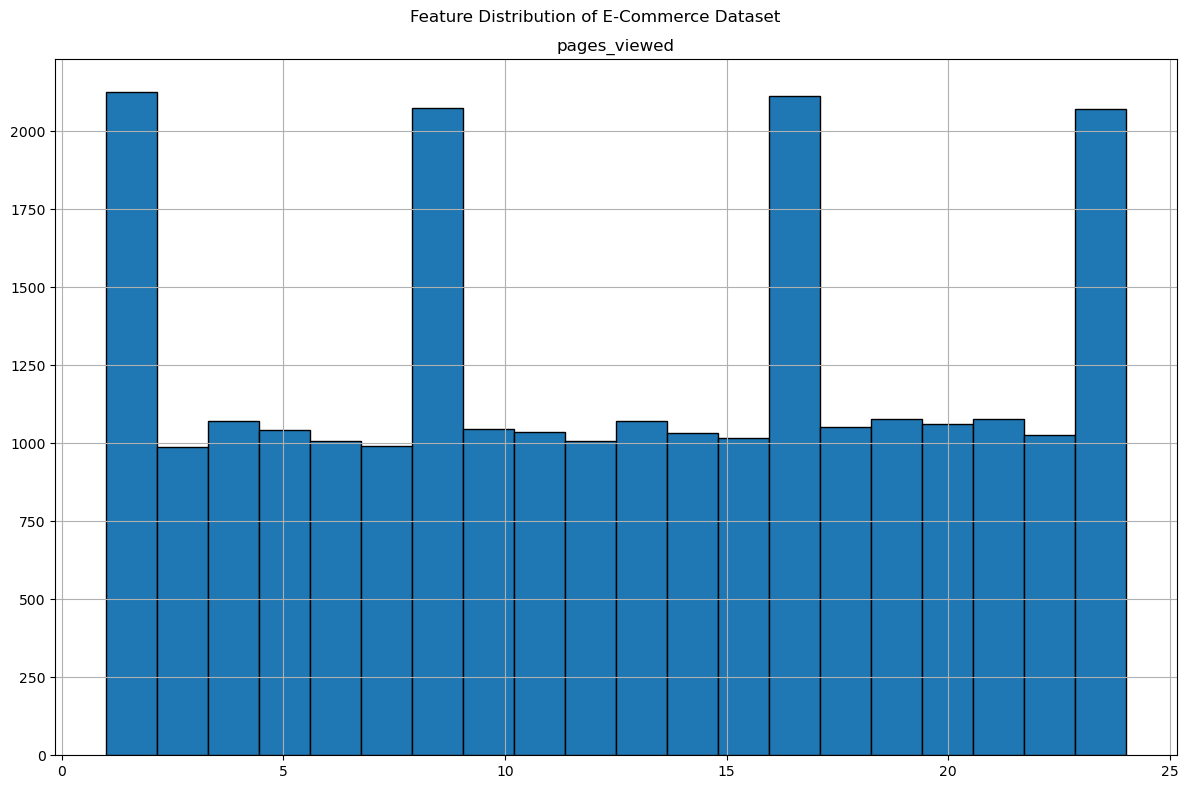

In [7]:
import matplotlib.pyplot as plt

features = ['age', 'session_duration', 'pages_viewed',
            'items_added_to_cart', 'total_purchases']

available_features = [col for col in features if col in df.columns]

df[available_features].hist(
    figsize=(12, 8),
    bins=20,
    edgecolor='black'
)

plt.suptitle('Feature Distribution of E-Commerce Dataset')
plt.tight_layout()
plt.show()

In [1]:
import os

graph_folder = "RetailIQ_Graphs"

if os.path.exists(graph_folder):
    print("Files in RetailIQ_Graphs:")
    for file in os.listdir(graph_folder):
        print(file)
else:
    print("RetailIQ_Graphs folder not found in the current location.")

Files in RetailIQ_Graphs:
.ipynb_checkpoints
01_example_graph.png
01_overall_business_metrics.png
02_monthly_revenue_trend.png
03_monthly_purchase_trend.png
04_category_revenue.png
05_marketing_channel_performance.png
06_device_purchase_behavior.png
07_customer_type_purchase_rate.png
08_shopping_journey_funnel.png
09_numerical_correlation_heatmap.png
10_discount_vs_revenue.png
11_session_duration_distribution.png
12_session_duration_by_purchase.png
13_category_purchase_counts.png
14_marketing_channel_conversion_rate.png
15_purchase_revenue_boxplot.png
16_pages_viewed_by_purchase_outcome.png
17_seasonal_purchase_rate.png
18_univariate_numerical_distributions.png
19_categorical_variable_distributions.png
20_shopping_behavior_distributions.png
21_pages_vs_time_by_purchase.png
22_discount_vs_purchase_rate.png
23_customer_device_purchase_heatmap.png
24_channel_customer_purchase_heatmap.png
25_rfm_distributions.png
26_optimal_cluster_selection.png
27_customer_segment_profiles.png
28_cluster_

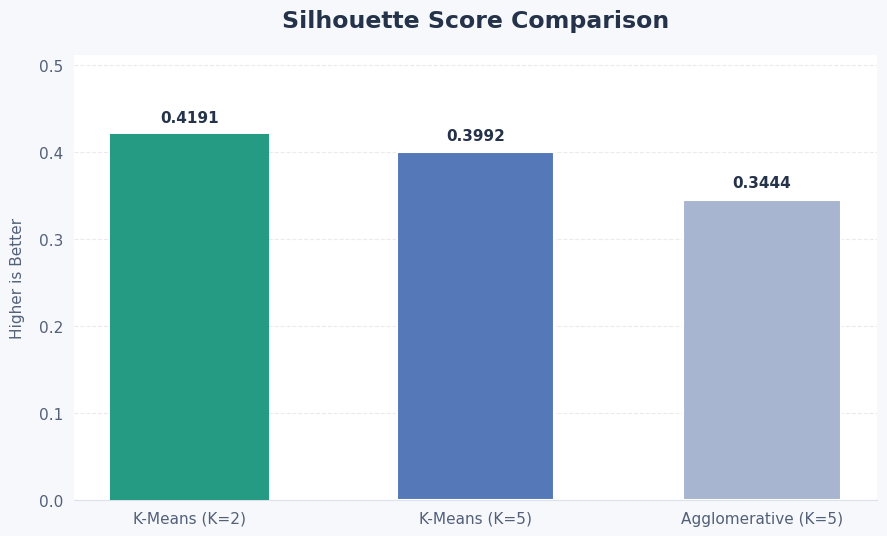

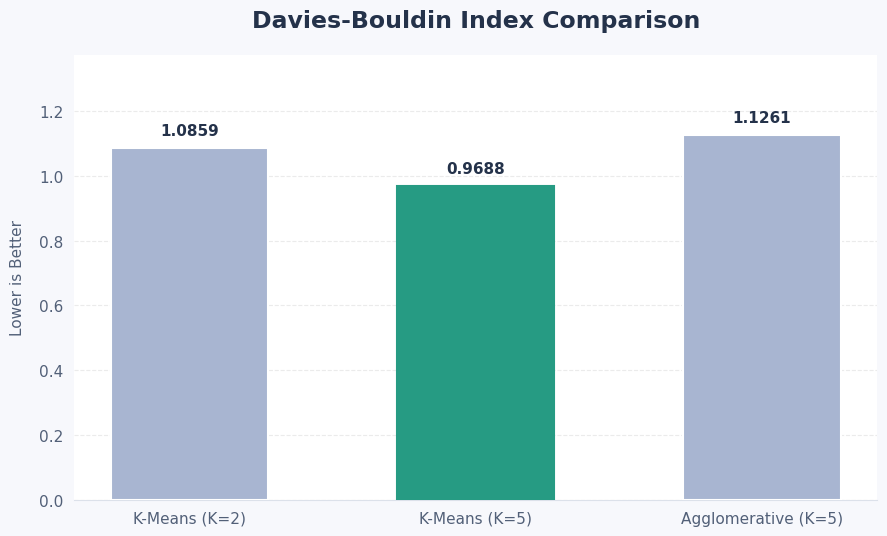

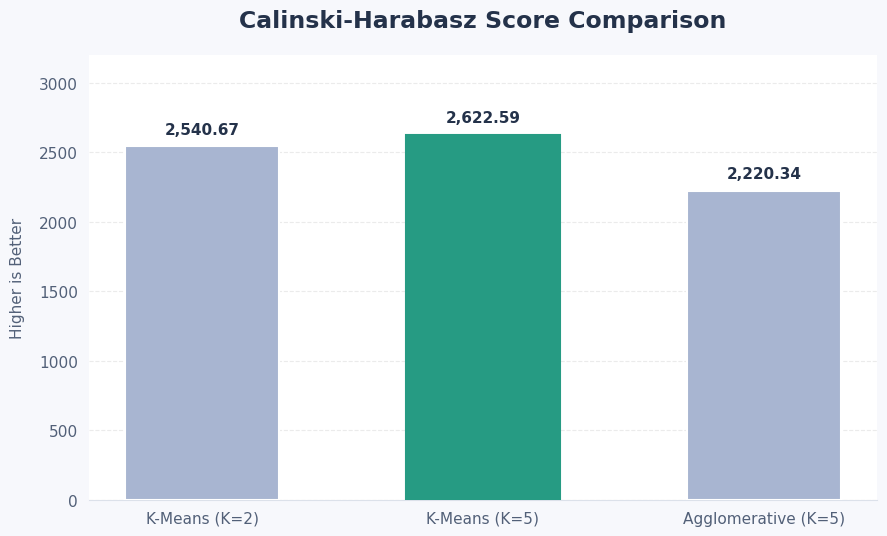

In [4]:
import matplotlib.pyplot as plt
import os

graph_folder = "RetailIQ_Graphs"
os.makedirs(graph_folder, exist_ok=True)

models = ["K-Means (K=2)", "K-Means (K=5)", "Agglomerative (K=5)"]

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 17,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "figure.facecolor": "#F7F8FC",
    "axes.facecolor": "#FFFFFF"
})

def create_comparison_chart(values, title, ylabel, filename, better):

    fig, ax = plt.subplots(figsize=(9, 5.5))

    colors = ["#A8B5D1", "#5478B8", "#A8B5D1"]

    bars = ax.bar(
        models, values,
        color=colors,
        width=0.55,
        edgecolor="white",
        linewidth=1.5,
        zorder=3
    )

    ax.set_title(title, pad=20, color="#24324A")
    ax.set_ylabel(ylabel, color="#526078", labelpad=10)

    ax.grid(axis="y", linestyle="--", alpha=0.25)
    ax.set_axisbelow(True)

    for bar, value in zip(bars, values):
        ax.annotate(
            f"{value:,.4f}" if value < 10 else f"{value:,.2f}",
            xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 7),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontweight="bold",
            color="#24324A",
            fontsize=11
        )

    best_index = values.index(
        max(values) if better == "higher" else min(values)
    )
    bars[best_index].set_color("#269B83")

    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)

    ax.spines["bottom"].set_color("#DCE1EA")
    ax.tick_params(axis="both", length=0, colors="#526078", pad=8)

    ax.set_ylim(0, max(values) * 1.22)

    plt.tight_layout()

    plt.savefig(
        os.path.join(graph_folder, filename),
        dpi=300,
        bbox_inches="tight",
        facecolor=fig.get_facecolor()
    )

    plt.show()
    plt.close()


# 1. Silhouette Score
create_comparison_chart(
    [0.4191, 0.3992, 0.3444],
    "Silhouette Score Comparison",
    "Higher is Better",
    "30_model_comparison_silhouette.png",
    "higher"
)

# 2. Davies-Bouldin Index
create_comparison_chart(
    [1.0859, 0.9688, 1.1261],
    "Davies-Bouldin Index Comparison",
    "Lower is Better",
    "31_model_comparison_davies_bouldin.png",
    "lower"
)

# 3. Calinski-Harabasz Score
create_comparison_chart(
    [2540.67, 2622.59, 2220.34],
    "Calinski-Harabasz Score Comparison",
    "Higher is Better",
    "32_model_comparison_calinski_harabasz.png",
    "higher"
)

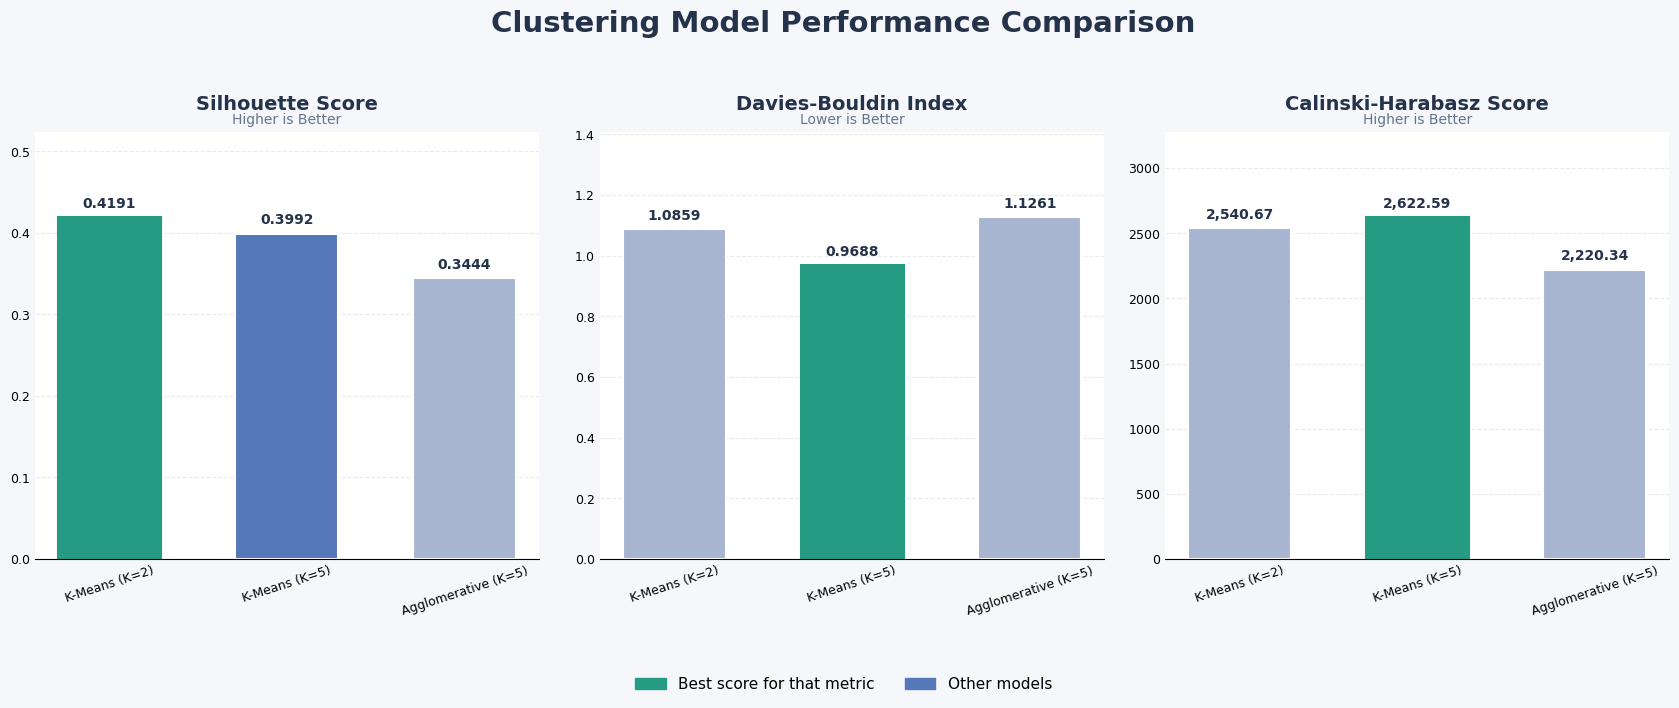

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import os

models = ["K-Means (K=2)", "K-Means (K=5)", "Agglomerative (K=5)"]

silhouette = [0.4191, 0.3992, 0.3444]
davies_bouldin = [1.0859, 0.9688, 1.1261]
calinski_harabasz = [2540.67, 2622.59, 2220.34]

fig, axes = plt.subplots(1, 3, figsize=(17, 6))
fig.patch.set_facecolor("#F5F7FB")

metrics = [
    (silhouette, "Silhouette Score", "Higher is Better", "higher"),
    (davies_bouldin, "Davies-Bouldin Index", "Lower is Better", "lower"),
    (calinski_harabasz, "Calinski-Harabasz Score", "Higher is Better", "higher")
]

colors = ["#A8B5D1", "#5478B8", "#A8B5D1"]

for ax, (values, title, subtitle, better) in zip(axes, metrics):

    ax.set_facecolor("white")

    bars = ax.bar(
        models,
        values,
        color=colors,
        width=0.58,
        edgecolor="white",
        linewidth=1.5
    )

    best_index = (
        values.index(max(values))
        if better == "higher"
        else values.index(min(values))
    )

    bars[best_index].set_color("#269B83")

    for bar, value in zip(bars, values):
        label = f"{value:.4f}" if value < 10 else f"{value:,.2f}"

        ax.annotate(
            label,
            xy=(bar.get_x() + bar.get_width()/2, bar.get_height()),
            xytext=(0, 7),
            textcoords="offset points",
            ha="center",
            fontsize=10,
            fontweight="bold",
            color="#24324A"
        )

    ax.set_title(title, fontsize=14, fontweight="bold",
                 color="#24324A", pad=16)

    ax.text(
        0.5, 1.02, subtitle,
        transform=ax.transAxes,
        ha="center",
        fontsize=10,
        color="#64748B"
    )

    ax.grid(axis="y", linestyle="--", alpha=0.25)
    ax.set_axisbelow(True)
    ax.tick_params(axis="x", rotation=18, labelsize=9, length=0)
    ax.tick_params(axis="y", labelsize=9, length=0)

    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)

    ax.set_ylim(0, max(values) * 1.25)

fig.suptitle(
    "Clustering Model Performance Comparison",
    fontsize=21,
    fontweight="bold",
    color="#24324A",
    y=1.04
)

fig.legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, color="#269B83"),
        plt.Rectangle((0, 0), 1, 1, color="#5478B8")
    ],
    labels=["Best score for that metric", "Other models"],
    loc="lower center",
    ncol=2,
    frameon=False,
    bbox_to_anchor=(0.5, -0.12)
)

plt.tight_layout()

plt.savefig(
    os.path.join("RetailIQ_Graphs",
                 "33_combined_model_comparison.png"),
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()
plt.close()

In [6]:
rfm.head()

NameError: name 'rfm' is not defined

In [7]:
%who_ls

['ax',
 'axes',
 'bar',
 'bars',
 'best_index',
 'better',
 'calinski_harabasz',
 'colors',
 'create_comparison_chart',
 'dataframe_columns',
 'dataframe_hash',
 'davies_bouldin',
 'dtypes_str',
 'fig',
 'file',
 'get_dataframes',
 'getpass',
 'graph_folder',
 'hashlib',
 'import_pandas_safely',
 'is_data_frame',
 'json',
 'label',
 'metrics',
 'models',
 'np',
 'os',
 'plt',
 'scores',
 'silhouette',
 'spine',
 'subtitle',
 'title',
 'value',
 'values']

In [8]:
dataframes = get_dataframes()

for name, df in dataframes.items():
    print(name, df.shape, list(df.columns))

AttributeError: 'str' object has no attribute 'items'

In [9]:
print(get_dataframes())

{"dataframes": [], "user": "vishu"}


In [10]:
%who DataFrame

No variables match your requested type.


In [11]:
import os

print(os.listdir())

['.ipynb_checkpoints', 'app.py', 'Batch 2 - DS Research Paper.docx', 'Batch 2-DS Abstract.docx', 'Batch 2-DS Abstract.pdf', 'Batch 2-DS PPT.pptx', 'DS PPTS', 'Ecommerce.csv', 'Implementation.ipynb', 'RetailIQ_Business_Recommendations.csv', 'RetailIQ_Customer_Segments.csv', 'RetailIQ_Feature_Set_Comparison.csv', 'RetailIQ_Graphs', 'RetailIQ_Implementation.ipynb', 'RetailIQ_Model_Comparison.csv', 'RetailIQ_processed.csv', 'RetailIQ_Segment_Summary.csv', 'Untitled.ipynb']


In [12]:
import pandas as pd

segments = pd.read_csv("RetailIQ_Customer_Segments.csv")

print(segments.shape)
print(segments.columns.tolist())
print(segments.head(10).to_string(index=False))

(4176, 6)
['customer_id', 'Recency', 'Frequency', 'Monetary', 'Cluster', 'Customer_Segment']
 customer_id  Recency  Frequency  Monetary  Cluster              Customer_Segment
        1000      248          1   1228.72        3  Inactive / At-Risk Customers
        1003       89          1   1681.96        1     Recent One-Time Customers
        1008       49          1   1546.42        1     Recent One-Time Customers
        1009      100          3   4616.63        2 High-Value Frequent Customers
        1014      318          1   2423.92        3  Inactive / At-Risk Customers
        1026      350          1    244.30        3  Inactive / At-Risk Customers
        1028      138          1   2328.44        1     Recent One-Time Customers
        1029      155          1    357.02        1     Recent One-Time Customers
        1031      129          2   2231.42        0              Repeat Customers
        1033      333          1    571.06        3  Inactive / At-Risk Customers


In [13]:
sample_output = (
    segments.groupby("Customer_Segment", group_keys=False)
    .head(2)
    .sort_values(["Cluster", "customer_id"])
)

ppt_output = sample_output[
    ["customer_id", "Recency", "Frequency", "Monetary", "Customer_Segment"]
]

print(ppt_output.to_string(index=False))

 customer_id  Recency  Frequency  Monetary                Customer_Segment
        1031      129          2   2231.42                Repeat Customers
        1039       15          2   1852.98                Repeat Customers
        1003       89          1   1681.96       Recent One-Time Customers
        1008       49          1   1546.42       Recent One-Time Customers
        1009      100          3   4616.63   High-Value Frequent Customers
        1040       14          2   7417.69   High-Value Frequent Customers
        1000      248          1   1228.72    Inactive / At-Risk Customers
        1014      318          1   2423.92    Inactive / At-Risk Customers
        1038       52          1   4503.98 High-Spending At-Risk Customers
        1065      223          1   7889.36 High-Spending At-Risk Customers
